## Setup Library dan Konfigurasi Path

In [82]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

# --- Path (relatif terhadap folder notebook/) ---
BASE_DIR   = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW_PATH   = BASE_DIR / "dataset" / "Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx"
PREP_PATH  = BASE_DIR / "dataset" / "KelpLOL_survey_prepared.csv"
DICT_PATH  = BASE_DIR / "dictionary" / "KelpLOL_data_dictionary.xlsx"
FIG_DIR    = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("pandas", pd.__version__)
print("File sumber ada:", RAW_PATH.exists(), "->", RAW_PATH.relative_to(BASE_DIR))

pandas 2.2.3
File sumber ada: True -> dataset\Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx


## 1. Data Understanding
Tujuan tahap ini adalah **memahami** isi dataset sebelum mengubah apa pun

| Sub-bagian | Poin spesifikasi |
|---|---|
| 1.1 | Ukuran dataset, contoh baris, nama kolom, tipe data, **statistik ringkas awal** |
| 1.2 | **Pengelompokan variabel** berdasarkan peran/jenis (metadata non-identifying, item survei, skor numerik, label/kategori) |
| 1.3 | **Nilai unik, kategori yang muncul, range numerik, konsistensi format** |
| 1.4 | Ringkasan temuan dan tindak lanjut |

Belum ada data yang diubah atau dihapus di tahap ini. `df_raw` hanya dibaca.

### 1.1 Ukuran dataset, contoh baris, nama kolom, tipe data, dan statistik ringkas awal
#### 1.1.1 Memuat data dan ukuran dataset

In [83]:
df_raw = pd.read_excel(RAW_PATH)  # data mentah: TIDAK diubah
print(f"Jumlah baris (responden): {df_raw.shape[0]}")
print(f"Jumlah kolom (variabel) : {df_raw.shape[1]}")

Jumlah baris (responden): 194
Jumlah kolom (variabel) : 116


#### 1.1.2 Contoh baris
Nama kolom berupa teks pertanyaan yang panjang, sehingga contoh baris ditampilkan **ditranspos** (kolom menjadi baris). Ditampilkan 3 responden pertama dan kolom perwakilan dari tiap bagian survei.

In [84]:
kolom_contoh = [0, 1, 2, 16, 17, 18, 49, 81, 104, 105, 109, 111, 114, 115]
df_raw.iloc[:3, kolom_contoh].T

,0,1,2
ID,1,2,3
"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...","melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me...","melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me...","melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me..."
"Saat harus memahami prosedur penggunaan suatu perangkat atau aplikasi, saya cenderung...",meminta seseorang menjelaskan langkah-langkahnya secara lisan.;mengikuti gam...,mengikuti gambar langkah demi langkah atau tangkapan layar.;meminta seseoran...,langsung mencoba sambil memperbaiki kesalahan yang muncul.;membaca petunjuk ...
"Jika harus memilih satu cara untuk mempelajari sesuatu yang benar-benar baru, saya akan memprioritaskan...",mendengar seseorang menjelaskannya dan berdialog.;,melihat representasi visual tentang bagaimana hal itu bekerja.;,melihat representasi visual tentang bagaimana hal itu bekerja.;
Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaimana hasilnya.,3.0,4.0,5.0
Saya lebih bersemangat ketika dapat langsung terlibat dalam tugas atau tantangan baru.,4.0,3.0,4.0
Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau mengerjakan sesuatu secara aktif.,4.0,5.0,4.0
Saya lebih mudah mulai belajar ketika memiliki pengalaman atau contoh konkret yang dapat saya amati.,4.0,3.0,5.0
Saya cenderung mengevaluasi keberhasilan ide berdasarkan hasil ketika ide tersebut diterapkan.,4.0,4.0,5.0
IPS 2022 Semester 1,NaN,NaN,NaN


#### 1.1.3 Nama kolom dan tipe data
`pos` adalah posisi kolom pada file asli (0 = kolom pertama) untuk menjaga keterlacakan. Tabel ini sekaligus menjadi dasar katalog variabel.

In [85]:
profil = pd.DataFrame({
    "pos": range(df_raw.shape[1]),
    "nama_kolom_asli": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "n_terisi": df_raw.notna().sum().values,
    "n_missing": df_raw.isna().sum().values,
    "n_unik": df_raw.nunique().values,
})
print("Rekap tipe data:")
print(profil["dtype"].value_counts().to_string())
profil

Rekap tipe data:
dtype
float64    99
object     16
int64       1


,pos,nama_kolom_asli,dtype,n_terisi,n_missing,n_unik
0,0,ID,int64,194,0,194
1,1,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",object,192,2,41
2,2,"Saat harus memahami prosedur penggunaan suatu perangkat atau aplikasi, saya ...",object,192,2,35
3,3,"Untuk mengingat materi menjelang ujian, saya biasanya lebih suka...",object,192,2,30
4,4,"Ketika dosen menjelaskan konsep abstrak, saya lebih mudah memahami bila...",object,192,2,33
...,...,...,...,...,...,...
111,111,IPS 2025 Semester 1,float64,173,21,139
112,112,IPS 2025 Semester 2,float64,172,22,138
113,113,IPS 2025 Semester 3,float64,16,178,6
114,114,IPS 2026 Semester 1,float64,173,21,1


**Bacaan:**
- `ID` bertipe integer.
- 16 kolom bertipe teks (`object`, atau `str` di pandas 3) berisi jawaban pilihan.
- 88 kolom `float64` dengan 4–5 nilai unik adalah skala Likert. Tipenya float karena pandas mengubah kolom integer yang mengandung `NaN` menjadi float.
- 11 kolom akademik `float64` berisi IPS per semester dan IPK.

#### 1.1.4 Statistik ringkas awal
Statistik dipisah menurut jenis kolom karena `describe()` gabungan tidak bermakna untuk kolom teks dan kolom numerik sekaligus.

**(a) Kolom teks/kategorikal (Q1–Q16):** `count`, jumlah nilai unik, nilai paling sering (`top`), dan frekuensinya.

In [86]:
vark_cols   = df_raw.columns[1:17]
likert_cols = df_raw.columns[17:105]
akad_cols   = df_raw.columns[105:116]

ringkas_kat = df_raw[vark_cols].describe().T
ringkas_kat.index = [f"q{i:03d}" for i in range(1, 17)]
ringkas_kat["top"] = ringkas_kat["top"].str.slice(0, 70) + "…"
ringkas_kat

,count,unique,top,freq
q001,192,41,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.;…,18
q002,192,35,mengikuti gambar langkah demi langkah atau tangkapan layar.;…,23
q003,192,30,"menulis ulang ringkasan, membuat daftar, atau membaca catatan.;berlati…",46
q004,192,33,ada visualisasi yang menunjukkan hubungan antar konsep.;…,29
q005,192,35,mendengarkan penjelasan dosen tentang apa yang harus dilakukan.;…,35
q006,192,39,bertanya kepada orang lain dan mendengarkan arahannya.;…,23
q007,192,39,"grafik, diagram, dan visualisasi pola.;tabel, uraian tertulis, dan pen…",17
q008,192,32,menjelaskannya melalui percakapan.;…,27
q009,192,31,"simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus.;…",28
q010,192,40,membicarakan masalah dengan orang lain untuk memperoleh ide.;…,25


`top` pada kolom multi-select adalah **kombinasi jawaban** yang paling sering muncul, bukan satu opsi. Frekuensi per opsi dibahas di 1.3.2.

**(b) Item Likert (Q17–Q104):** statistik per item, lalu rekap per framework agar 88 item mudah dibaca.

In [87]:
ringkas_lik = df_raw[likert_cols].describe().T
ringkas_lik.index = [f"q{i:03d}" for i in range(17, 105)]
ringkas_lik.round(2)

,count,mean,std,min,25%,50%,75%,max
q017,192.0,3.79,0.88,1.0,3.0,4.0,4.00,5.0
q018,192.0,3.89,0.88,1.0,3.0,4.0,5.00,5.0
q019,192.0,3.71,0.93,1.0,3.0,4.0,4.00,5.0
q020,192.0,3.85,0.87,1.0,3.0,4.0,4.00,5.0
q021,192.0,3.94,0.89,1.0,3.0,4.0,5.00,5.0
...,...,...,...,...,...,...,...,...
q100,192.0,3.77,0.87,1.0,3.0,4.0,4.00,5.0
q101,192.0,3.87,0.84,1.0,3.0,4.0,4.00,5.0
q102,192.0,3.95,0.82,1.0,3.0,4.0,5.00,5.0
q103,192.0,3.79,0.92,1.0,3.0,4.0,5.00,5.0


In [88]:
fw_item = pd.Series(["Honey-Mumford"] * 32 + ["Felder-Silverman"] * 32 + ["Kolb"] * 24, index=ringkas_lik.index)
rekap_lik = ringkas_lik.groupby(fw_item, sort=False).agg(
    n_item=("mean", "size"),
    mean_terendah=("mean", "min"), mean_tertinggi=("mean", "max"),
    std_terendah=("std", "min"),   std_tertinggi=("std", "max"),
    median_terbanyak=("50%", lambda s: s.mode().iat[0]),
)
rekap_lik.round(2)

,n_item,mean_terendah,mean_tertinggi,std_terendah,std_tertinggi,median_terbanyak
Honey-Mumford,32,3.26,4.24,0.79,1.00,4.0
Felder-Silverman,32,3.32,4.19,0.82,1.01,4.0
Kolb,24,3.63,4.09,0.79,0.98,4.0


In [89]:
print("5 item dengan rata-rata terendah:")
print(ringkas_lik["mean"].nsmallest(5).round(2).to_string())
print("\n5 item dengan rata-rata tertinggi:")
print(ringkas_lik["mean"].nlargest(5).round(2).to_string())

5 item dengan rata-rata terendah:
q030    3.26
q064    3.32
q071    3.57
q080    3.60
q078    3.60

5 item dengan rata-rata tertinggi:
q035    4.24
q043    4.19
q044    4.19
q058    4.19
q028    4.18


Rata-rata item Likert berada di rentang 3,26–4,24 (item terendah q030 dan q064, tertinggi q035) dan median hampir semua item adalah 4, artinya responden cenderung setuju terhadap pernyataan. Statistik ini hanya **gambaran item**. Skor dimensi framework belum dihitung karena memerlukan aturan scoring (Tahap 3).

**(c) Kolom akademik (IPS dan IPK):**

In [90]:
ringkas_akad = df_raw[akad_cols].describe().T
ringkas_akad["n_missing"] = df_raw[akad_cols].isna().sum()
ringkas_akad["n_nilai_0"] = (df_raw[akad_cols] == 0).sum()
ringkas_akad.round(3)

,count,mean,std,min,25%,50%,75%,max,n_missing,n_nilai_0
IPS 2022 Semester 1,1.0,3.026,NaN,3.026,3.026,3.026,3.026,3.026,193,0
IPS 2022 Semester 2,1.0,3.133,NaN,3.133,3.133,3.133,3.133,3.133,193,0
IPS 2023 Semester 1,18.0,3.490,0.384,2.679,3.203,3.620,3.728,3.967,176,0
IPS 2023 Semester 2,18.0,3.550,0.333,2.833,3.358,3.564,3.796,4.000,176,0
IPS 2024 Semester 1,125.0,3.334,0.373,2.257,3.132,3.343,3.594,4.000,69,0
IPS 2024 Semester 2,125.0,3.371,0.495,0.952,3.181,3.439,3.709,4.000,69,0
IPS 2025 Semester 1,173.0,3.294,0.556,0.867,3.010,3.400,3.717,4.000,21,0
IPS 2025 Semester 2,172.0,3.471,0.464,0.940,3.225,3.590,3.819,4.000,22,0
IPS 2025 Semester 3,16.0,3.469,0.429,3.000,3.000,3.500,3.891,4.000,178,0
IPS 2026 Semester 1,173.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,21,173


Jumlah terisi per kolom IPS sangat bervariasi (1 sampai 173) karena tiap responden hanya punya IPS untuk semester yang sudah dijalani. `IPS 2026 Semester 1` memiliki mean dan std = 0 (seluruh nilainya 0), dan dianalisis lebih lanjut di 1.3.3.

### 1.2 Pengelompokan variabel berdasarkan peran/jenis
#### 1.2.1 Pemeriksaan identifier (dasar untuk menyebut metadata "non-identifying")
Sebelum mengelompokkan, kita pastikan tidak ada kolom yang dapat langsung mengidentifikasi responden.

In [91]:
pola_pii = r"nama|name|npm|nim|email|e-mail|telp|telepon|phone|whatsapp|username|alamat|start time|completion time"
kolom_pii = [c for c in df_raw.columns if re.search(pola_pii, str(c), flags=re.I)]
print("Kolom yang namanya mengindikasikan identitas:", kolom_pii if kolom_pii else "TIDAK ADA")

id_col = df_raw["ID"]
print(f"ID unik: {id_col.is_unique} | range {id_col.min()}–{id_col.max()} | "
      f"nomor urut 1..n: {id_col.tolist() == list(range(1, len(df_raw) + 1))}")

Kolom yang namanya mengindikasikan identitas: TIDAK ADA
ID unik: True | range 1–194 | nomor urut 1..n: True


Tidak ada kolom nama, NPM, email, telepon, atau waktu pengisian. `ID` hanya nomor urut, sehingga dipakai sebagai **kunci teknis** dan bukan variabel analisis.

#### 1.2.2 Peran variabel menurut kategori spesifikasi
Spesifikasi (Bagian 7.3) membagi kolom menjadi 5 jenis. Pemetaan dataset ini:

| Jenis kolom (spesifikasi) | Ada di dataset? | Kolom |
|---|---|---|
| 1. Metadata non-identifying | Ya | `ID` (kunci teknis), 10 kolom IPS dan `IPK` (konteks akademik numerik) |
| 2. Raw/coded survey items | Ya | Q1–Q16 (pilihan VARK, teks) dan Q17–Q104 (Likert 1–5) |
| 3. Scores/dimensions | **Tidak** | Belum ada skor VARK/Kolb/FS/HM yang dihitung dosen, jadi perlu diturunkan (derived) |
| 4. Labels/profiles | **Tidak** | Belum ada label gaya belajar, jadi perlu diturunkan sesuai aturan dosen |
| 5. Prepared variables | Belum | Akan dibuat di Tahap 2–3 (mis. kode kolom, indikator opsi VARK) |

Item survei terbagi ke empat framework. Pembagian item ke dimensi berikut awalnya disusun dari isi item, lalu **dicocokkan dengan kolom Excel pada panduan dosen** (*Panduan Tugas Klasifikasi Preferensi Belajar*) dan hasilnya sama persis (diverifikasi di 3.4).

| Blok | Posisi | Jenis jawaban | Framework dan dimensi |
|---|---|---|---|
| Q1–Q16 | 1–16 | Multi-select, 4 opsi | **VARK**: opsi mewakili Visual, Aural, Read/Write, Kinesthetic |
| Q17–Q48 | 17–48 | Likert 1–5 | **Honey-Mumford**: Activist, Reflector, Theorist, Pragmatist (8 item per dimensi) |
| Q49–Q80 | 49–80 | Likert 1–5 | **Felder-Silverman**: Active, Reflective, Sensing, Intuitive, Visual, Verbal, Sequential, Global (4 item per dimensi) |
| Q81–Q104 | 81–104 | Likert 1–5 | **Kolb**: CE, RO, AC, AE (6 item per dimensi) |

In [92]:
def blok_item(q):
    # q = nomor item 1..104 -> (framework, dimensi; sesuai panduan dosen)
    if 1 <= q <= 16:
        return "VARK", "multi-select (V/A/R/K)"
    if 17 <= q <= 48:
        return "Honey-Mumford", ["Activist", "Reflector", "Theorist", "Pragmatist"][(q - 17) // 8]
    if 49 <= q <= 80:
        return "Felder-Silverman", ["Active", "Reflective", "Sensing", "Intuitive",
                                    "Visual", "Verbal", "Sequential", "Global"][(q - 49) // 4]
    if 81 <= q <= 104:
        return "Kolb", ["Concrete Experience (CE)", "Reflective Observation (RO)",
                        "Abstract Conceptualization (AC)", "Active Experimentation (AE)"][(q - 81) // 6]

def kode_akademik(nama):
    m = re.match(r"IPS (\d{4}) Semester (\d)", nama)
    return f"ips_{m.group(1)}_s{m.group(2)}" if m else nama.lower()

katalog = []
for pos, col in enumerate(df_raw.columns):
    if pos == 0:
        katalog.append((col, "id", "Metadata non-identifying (kunci teknis)", "Kategorikal (ID)", "-", "-"))
    elif pos <= 16:
        fw, dim = blok_item(pos)
        katalog.append((col, f"q{pos:03d}", "Raw survey item", "Kategorikal multi-select (teks)", fw, dim))
    elif pos <= 104:
        fw, dim = blok_item(pos)
        katalog.append((col, f"q{pos:03d}", "Raw survey item", "Ordinal (Likert 1–5)", fw, dim))
    else:
        katalog.append((col, kode_akademik(col), "Metadata non-identifying (konteks akademik)",
                        "Numerik kontinu (0–4)", "-", "-"))

katalog = pd.DataFrame(katalog, columns=["nama_kolom_asli", "kode_usulan", "peran",
                                         "jenis_data", "framework", "dimensi"])
katalog.insert(0, "pos", range(len(katalog)))
katalog = katalog.merge(profil[["pos", "dtype", "n_terisi", "n_missing", "n_unik"]], on="pos")

display(katalog.groupby(["peran", "jenis_data", "framework"], sort=False).size()
        .rename("jumlah_kolom").to_frame())
display(katalog.query("framework in ['Honey-Mumford','Felder-Silverman','Kolb']")
        .groupby(["framework", "dimensi"], sort=False).size().rename("jumlah_item").to_frame())

jumlah_kolom
peran                                       jenis_data                      framework                     
Metadata non-identifying (kunci teknis)     Kategorikal (ID)                -                            1
Raw survey item                             Kategorikal multi-select (teks) VARK                        16
                                            Ordinal (Likert 1–5)            Honey-Mumford               32
                                                                            Felder-Silverman            32
                                                                            Kolb                        24
Metadata non-identifying (konteks akademik) Numerik kontinu (0–4)           -                           11

jumlah_item
framework        dimensi                                     
Honey-Mumford    Activist                                   8
                 Reflector                                  8
                 Theorist                                   8
                 Pragmatist                                 8
Felder-Silverman Active                                     4
                 Reflective                                 4
                 Sensing                                    4
                 Intuitive                                  4
                 Visual                                     4
                 Verbal                                     4
                 Sequential                                 4
                 Global                                     4
Kolb             Concrete Experience (CE)                   6
                 Reflective Observation (RO)                6
                 Abstract Conceptualization (AC)            6
                 Active Experimentation (AE)                6

Total 116 kolom = 1 ID + 16 item VARK + 32 item Honey-Mumford + 32 item Felder-Silverman + 24 item Kolb + 11 kolom akademik. Jumlah item per dimensi seimbang di tiap framework. **Skor dan label belum tersedia**, sehingga distribusi skor/label di EDA bergantung pada derived variables Tahap 3.

### 1.3 Nilai unik, kategori yang muncul, range numerik, dan konsistensi format
#### 1.3.1 Ringkasan jumlah nilai unik per kelompok

In [93]:
katalog.groupby("jenis_data", sort=False)["n_unik"].describe()[["count", "min", "50%", "max"]] \
       .rename(columns={"count": "n_kolom", "50%": "median"}).astype(int)

,n_kolom,min,median,max
jenis_data,,,,
Kategorikal (ID),1,194,194,194
Kategorikal multi-select (teks),16,30,36,41
Ordinal (Likert 1–5),88,4,5,5
Numerik kontinu (0–4),11,1,18,139


- **ID**: 194 nilai unik, sama dengan jumlah baris (tidak ada ID ganda).
- **VARK**: 30–41 nilai unik per kolom, karena yang dihitung adalah *kombinasi* jawaban (lihat 1.3.2).
- **Likert**: 4–5 nilai unik, sesuai skala 5 poin.
- **Akademik**: bervariasi. `IPS 2026 Semester 1` hanya punya 1 nilai unik (0).

#### 1.3.2 Kategori yang muncul pada item VARK (Q1–Q16)
Microsoft Forms menyimpan jawaban *pilih lebih dari satu* sebagai teks yang dipisah titik koma, misalnya `"opsi A;opsi B;"`. Jawaban dipecah per opsi untuk melihat kategori sebenarnya.

In [94]:
def pecah_opsi(x):
    # pisah jawaban multi-select; abaikan string kosong setelah ';' terakhir
    return [o for o in str(x).split(";") if o != ""] if pd.notna(x) else []

rows = []
for i, c in enumerate(vark_cols, start=1):
    s = df_raw[c].map(pecah_opsi).explode().dropna()
    for opsi, n in s.value_counts().items():
        rows.append((f"q{i:03d}", c[:55] + "…", opsi, n))
opsi_vark = pd.DataFrame(rows, columns=["kode", "pertanyaan", "opsi", "frekuensi"])
print("Jumlah opsi berbeda per pertanyaan:", opsi_vark.groupby("kode").size().unique())
opsi_vark

Jumlah opsi berbeda per pertanyaan: [4]


,kode,pertanyaan,opsi,frekuensi
0,q001,"Ketika mempelajari topik baru yang cukup kompleks, saya…","mencoba contoh, simulasi, praktik, atau melihat penerapan nyata.",121
1,q001,"Ketika mempelajari topik baru yang cukup kompleks, saya…",mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.,113
2,q001,"Ketika mempelajari topik baru yang cukup kompleks, saya…","melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.",92
3,q001,"Ketika mempelajari topik baru yang cukup kompleks, saya…","membaca uraian tertulis, definisi, atau catatan yang terstruktur.",80
4,q002,Saat harus memahami prosedur penggunaan suatu perangkat…,mengikuti gambar langkah demi langkah atau tangkapan layar.,107
...,...,...,...,...
59,q015,"Dalam kerja kelompok, saya biasanya berkontribusi palin…","menyusun bagan, desain, atau struktur visual.",72
60,q016,Jika harus memilih satu cara untuk mempelajari sesuatu …,melihat representasi visual tentang bagaimana hal itu bekerja.,113
61,q016,Jika harus memilih satu cara untuk mempelajari sesuatu …,mendengar seseorang menjelaskannya dan berdialog.,94
62,q016,Jika harus memilih satu cara untuk mempelajari sesuatu …,mengalami atau mencoba secara langsung.,80


In [95]:
n_pilih = df_raw[vark_cols].apply(lambda s: s.map(lambda x: len(pecah_opsi(x)) if pd.notna(x) else np.nan))
dist = n_pilih.stack().value_counts().sort_index()
dist.index = dist.index.astype(int)
print("Banyaknya opsi yang dipilih per jawaban (seluruh 16 pertanyaan):")
print(dist.rename("jumlah_jawaban").to_frame()
      .assign(persen=lambda t: (t.jumlah_jawaban / t.jumlah_jawaban.sum() * 100).round(1)).to_string())

Banyaknya opsi yang dipilih per jawaban (seluruh 16 pertanyaan):
   jumlah_jawaban  persen
1            1048    34.1
2            1320    43.0
3             526    17.1
4             178     5.8


Setiap pertanyaan memiliki **tepat 4 opsi**, dan tidak ada opsi tambahan atau ejaan berbeda untuk opsi yang sama. Sekitar 77% jawaban memilih 1–2 opsi. Memilih 3–4 opsi tetap **jawaban sah** karena instrumen mengizinkan multi-pilihan.

#### 1.3.3 Range variabel numerik terhadap range valid
Range valid diambil dari struktur instrumen/data: Likert **1–5** (bilangan bulat), IPS/IPK **0,00–4,00**.

In [96]:
cek_range = pd.DataFrame({
    "kelompok": ["Likert (88 item)", "IPS (10 kolom)", "IPK"],
    "range_valid": ["1–5, bulat", "0–4", "0–4"],
    "min_teramati": [df_raw[likert_cols].min().min(), df_raw[akad_cols[:-1]].min().min(), df_raw["IPK"].min()],
    "max_teramati": [df_raw[likert_cols].max().max(), df_raw[akad_cols[:-1]].max().max(), df_raw["IPK"].max()],
})
lik_vals = df_raw[likert_cols].stack().dropna()   # dropna: konsisten di pandas 2 & 3
cek_range["n_di_luar_range"] = [
    (~lik_vals.isin([1, 2, 3, 4, 5])).sum(),
    ((df_raw[akad_cols[:-1]] < 0) | (df_raw[akad_cols[:-1]] > 4)).sum().sum(),
    ((df_raw["IPK"] < 0) | (df_raw["IPK"] > 4)).sum(),
]
cek_range

,kelompok,range_valid,min_teramati,max_teramati,n_di_luar_range
0,Likert (88 item),"1–5, bulat",1.0,5.0,0
1,IPS (10 kolom),0–4,0.0,4.0,0
2,IPK,0–4,0.0,4.0,0


In [97]:
print("Distribusi semua jawaban Likert:")
print(lik_vals.value_counts().sort_index().rename("n").to_frame()
      .assign(persen=lambda t: (t.n / t.n.sum() * 100).round(1)).to_string())
print("\nItem Likert yang tidak pernah dijawab 1:", (df_raw[likert_cols].min() > 1).sum(), "item")

Distribusi semua jawaban Likert:
        n  persen
1.0   166     1.0
2.0   710     4.2
3.0  4387    26.0
4.0  6862    40.6
5.0  4771    28.2

Item Likert yang tidak pernah dijawab 1: 11 item


In [98]:
# Nilai 0 pada akademik: valid secara range, tetapi perlu dicek maknanya
ips_hist = list(akad_cols[:-2])            # IPS 2022 S1 .. IPS 2025 S3
punya_riwayat = df_raw[ips_hist].notna().any(axis=1)
print("IPS 2026 Semester 1 -> nilai unik:", df_raw["IPS 2026 Semester 1"].dropna().unique())
print("\nResponden dengan IPK = 0:")
print(df_raw.loc[df_raw["IPK"] == 0, ["ID", "IPS 2026 Semester 1", "IPK"]]
      .assign(punya_riwayat_IPS=punya_riwayat).to_string(index=False))

print("\nNilai IPS terendah (> 0) yang teramati:")
print(df_raw.set_index("ID")[ips_hist].stack().loc[lambda s: s > 0].nsmallest(5).round(3).to_string())

IPS 2026 Semester 1 -> nilai unik: [0.]

Responden dengan IPK = 0:
 ID  IPS 2026 Semester 1  IPK  punya_riwayat_IPS
 20                  0.0  0.0              False
 29                  0.0  0.0              False
 59                  0.0  0.0              False
 82                  0.0  0.0              False

Nilai IPS terendah (> 0) yang teramati:
ID                      
30   IPS 2025 Semester 1    0.867
4    IPS 2025 Semester 1    0.905
134  IPS 2025 Semester 2    0.940
4    IPS 2024 Semester 2    0.952
175  IPS 2024 Semester 2    1.280


**Bacaan range:**
- Tidak ada nilai di luar range valid, baik pada Likert maupun IPS/IPK.
- Nilai Likert condong ke setuju: skor 4–5 sekitar 69% dan skor 1 hanya 1%.
- **`IPS 2026 Semester 1` seluruhnya 0.** Semester ini sedang berjalan, sehingga 0 berarti *nilai belum keluar*, bukan IPS 0,00.
- **`IPK = 0` pada 4 responden** (ID 20, 29, 59, 82) yang tidak punya riwayat IPS. Kemungkinan besar mereka mahasiswa baru, sehingga 0 berarti *belum ada IPK*.
- Nilai 0 ini lolos cek range tetapi **maknanya keliru**. Penanganannya diputuskan di Tahap 2.
- IPS rendah seperti 0,87 masih **mungkin** (ekstrem tetapi valid), jadi tidak dianggap error.

#### 1.3.4 Konsistensi format
Yang diperiksa: format jawaban VARK, bilangan bulat pada Likert, presisi desimal IPS/IPK, nama kolom, dan format ID.

In [99]:
# (a) VARK: separator, spasi tepi, kapitalisasi, tanda titik di akhir opsi
semua_opsi = [o for c in vark_cols for x in df_raw[c].dropna() for o in pecah_opsi(x)]
format_vark = pd.Series({
    "semua jawaban diakhiri ';'":          all(df_raw[c].dropna().str.endswith(";").all() for c in vark_cols),
    "ada spasi di tepi opsi":              any(o != o.strip() for o in semua_opsi),
    "semua opsi diawali huruf kecil":      all(o[0].islower() for o in semua_opsi),
    "semua opsi diakhiri titik":           all(o.endswith(".") for o in semua_opsi),
    "jumlah opsi berbeda per pertanyaan":  sorted(opsi_vark.groupby("kode").size().unique().tolist()),
}, name="hasil")
print("(a) Format jawaban VARK"); print(format_vark.to_string())

# (b) Likert: bilangan bulat?
print("\n(b) Semua nilai Likert bilangan bulat:", bool((lik_vals % 1 == 0).all()))

# (c) Presisi desimal IPS/IPK
def n_desimal(v):
    return len(repr(float(v)).split(".")[1].rstrip("0"))
presisi = df_raw[akad_cols].apply(lambda s: s.dropna().map(n_desimal).value_counts()).fillna(0).astype(int).T
presisi.columns = [f"{int(c)} desimal" for c in presisi.columns]
print("\n(c) Jumlah nilai menurut banyaknya digit desimal:")
print(presisi.sort_index(axis=1).to_string())

# (d) Nama kolom
print("\n(d) Nama kolom dengan spasi ganda/di tepi:",
      [c for c in df_raw.columns if c != c.strip() or "  " in c] or "TIDAK ADA")
print("    Nama kolom duplikat:", df_raw.columns.duplicated().sum())
print("    Panjang nama kolom: min", min(map(len, df_raw.columns)), "| max", max(map(len, df_raw.columns)), "karakter")

(a) Format jawaban VARK
semua jawaban diakhiri ';'             True
ada spasi di tepi opsi                False
semua opsi diawali huruf kecil         True
semua opsi diakhiri titik              True
jumlah opsi berbeda per pertanyaan      [4]

(b) Semua nilai Likert bilangan bulat: True

(c) Jumlah nilai menurut banyaknya digit desimal:
                     0 desimal  1 desimal  2 desimal  3 desimal  4 desimal  5 desimal  6 desimal
IPS 2022 Semester 1          0          0          0          0          0          0          1
IPS 2022 Semester 2          0          0          0          0          0          0          1
IPS 2023 Semester 1          0          2          4          0          0          0         12
IPS 2023 Semester 2          1          2          2          0          0          1         12
IPS 2024 Semester 1          2          5         19          0          1          4         94
IPS 2024 Semester 2          7          5         20          3          0    

**Bacaan konsistensi format:**
- **VARK konsisten.** Semua jawaban memakai separator `;` di akhir, tanpa spasi berlebih, kapitalisasi seragam, dan 4 opsi per pertanyaan. Tidak perlu normalisasi teks.
- **Likert konsisten.** Semua nilai bilangan bulat. Tipe `float64` hanya akibat `NaN`, jadi cukup dikonversi ke integer nullable (`Int64`) di Tahap 2.
- **Presisi IPS tidak seragam.** Sebagian besar tersimpan dengan 6 desimal (mis. 3.026315), sebagian lain 0–2 desimal (mis. 3.88). Ini perbedaan format, bukan perbedaan makna. Nilai tidak dibulatkan agar informasi asli tetap terjaga, dan cukup dibulatkan saat ditampilkan. IPK konsisten maksimal 2 desimal.
- **Nama kolom** tidak duplikat dan tanpa spasi bermasalah, tetapi sangat panjang (teks pertanyaan) sehingga perlu kode singkat (`q001`…) di Tahap 3, dengan pemetaan ke nama asli disimpan di data dictionary.

#### 1.3.5 Gambaran kelengkapan per baris

In [100]:
item_cols = df_raw.columns[1:105]
miss_per_baris = df_raw[item_cols].isna().sum(axis=1)
print("Jumlah item survei kosong per responden -> banyaknya responden:")
print(miss_per_baris.value_counts().sort_index().to_string())
print("ID responden dengan seluruh 104 item kosong:", df_raw.loc[miss_per_baris == 104, "ID"].tolist())

Jumlah item survei kosong per responden -> banyaknya responden:
0      192
104      2
ID responden dengan seluruh 104 item kosong: [11, 133]


Responden hanya terbagi dua: **lengkap** (0 item kosong) atau **kosong total** (104 item). Tidak ada pengisian parsial. Dua respons kosong (ID 11 dan 133) ditangani di Tahap 2.

### 1.4 Ringkasan temuan Data Understanding
| # | Poin spesifikasi | Temuan | Tindak lanjut |
|---|---|---|---|
| 1 | Ukuran & tipe | 194 baris × 116 kolom; 1 int, 16 teks, 99 float | Likert dikonversi ke `Int64` (Tahap 2) |
| 2 | Statistik awal | Likert condong setuju (median 4); IPS rata-rata ±3,3–3,5 | Dianalisis lebih dalam di EDA |
| 3 | Peran variabel | Metadata non-identifying (ID, IPS, IPK) + 104 item survei; **belum ada skor & label** | Skor/label diturunkan di Tahap 3 dengan aturan dosen |
| 4 | Identifier | Tidak ada PII; `ID` = nomor urut | `ID` hanya kunci teknis |
| 5 | Kategori | VARK: tepat 4 opsi per pertanyaan, multi-select | Parsing ke indikator biner per opsi (Tahap 3) |
| 6 | Range | Tidak ada nilai di luar range | – |
| 7 | Range (makna) | `IPS 2026 Semester 1` seluruhnya 0; `IPK = 0` pada 4 responden tanpa riwayat | Tandai sebagai *belum tersedia* (Tahap 2) |
| 8 | Format | VARK & Likert konsisten; presisi desimal IPS tidak seragam | Tidak dibulatkan; dicatat di dictionary |
| 9 | Format | Nama kolom = teks pertanyaan panjang | Rename ke kode `q001…` + mapping (Tahap 3) |
| 10 | Kelengkapan | 2 respons kosong total (ID 11, 133); sisanya lengkap | Validasi & penghapusan tercatat (Tahap 2) |
| 11 | Framework | Pemetaan item ke dimensi disusun dari isi item | Dicocokkan dengan panduan scoring dosen (3.4): sama persis |

## 2. Data Cleaning dan Validasi
Semua proses bekerja pada salinan **`df`**; `df_raw` tetap utuh sebagai data sumber. Setiap perubahan dicatat lewat fungsi `catat()` ke **cleaning log**, lengkap dengan jumlah baris/kolom sebelum dan sesudah serta alasannya. Pemeriksaan yang tidak menghasilkan perubahan juga dicatat, sebagai bukti bahwa pemeriksaan sudah dilakukan.

| Sub-bagian | Pemeriksaan |
|---|---|
| 2.1 | Missing value dan respons kosong |
| 2.2 | Duplikasi |
| 2.3 | Validasi range dan opsi jawaban (nilai tidak valid) |
| 2.4 | Kategori tidak konsisten dan normalisasi teks |
| 2.5 | Konversi tipe data |
| 2.6 | Nilai ekstrem: valid tetapi ekstrem vs tidak mungkin |
| 2.7 | Ringkasan dan cleaning log |

In [101]:
df = df_raw.copy()          # salinan kerja; df_raw tidak disentuh
log_rows = []

def catat(aksi, kolom, alasan, baris_sebelum, baris_sesudah, kolom_sebelum, kolom_sesudah, n_sel=0, tahap="2. Cleaning"):
    # Tambahkan satu entri ke cleaning log
    log_rows.append({
        "step_id": f"C{len(log_rows) + 1:02d}", "tahap": tahap, "aksi": aksi,
        "kolom_terdampak": kolom, "alasan": alasan,
        "n_baris_sebelum": baris_sebelum, "n_baris_sesudah": baris_sesudah,
        "n_kolom_sebelum": kolom_sebelum, "n_kolom_sesudah": kolom_sesudah,
        "n_sel_berubah": n_sel,
    })

print("Ukuran awal df:", df.shape)

Ukuran awal df: (194, 116)


### 2.1 Missing value dan respons kosong
#### 2.1.1 Missing per kelompok kolom

In [102]:
def ringkas_missing(data):
    grup = {"Item VARK (Q1–Q16)": vark_cols, "Item Likert (Q17–Q104)": likert_cols,
            "IPS (10 kolom)": [c for c in akad_cols if c.startswith("IPS")], "IPK": ["IPK"]}
    return pd.DataFrame({
        "n_kolom": {g: len(c) for g, c in grup.items()},
        "total_sel_missing": {g: int(data[list(c)].isna().sum().sum()) for g, c in grup.items()},
        "missing_min_per_kolom": {g: int(data[list(c)].isna().sum().min()) for g, c in grup.items()},
        "missing_max_per_kolom": {g: int(data[list(c)].isna().sum().max()) for g, c in grup.items()},
    })
ringkas_missing(df)

,n_kolom,total_sel_missing,missing_min_per_kolom,missing_max_per_kolom
Item VARK (Q1–Q16),16,32,2,2
Item Likert (Q17–Q104),88,176,2,2
IPS (10 kolom),10,1118,21,193
IPK,1,17,17,17


Item survei memiliki pola missing yang seragam (tepat 2 per kolom), sedangkan IPS/IPK missing dalam jumlah besar dan bervariasi. Keduanya punya penyebab berbeda, sehingga ditangani terpisah.

#### 2.1.2 Respons kosong
Respons kosong adalah responden yang **tidak menjawab satu pun** dari 104 item survei.

In [103]:
item_cols = list(vark_cols) + list(likert_cols)
kosong = df[item_cols].isna().all(axis=1)
print("Jumlah respons kosong:", kosong.sum())
df.loc[kosong, ["ID"] + list(akad_cols)]

Jumlah respons kosong: 2


,ID,IPS 2022 Semester 1,IPS 2022 Semester 2,IPS 2023 Semester 1,IPS 2023 Semester 2,IPS 2024 Semester 1,IPS 2024 Semester 2,IPS 2025 Semester 1,IPS 2025 Semester 2,IPS 2025 Semester 3,IPS 2026 Semester 1,IPK
10,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
132,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


ID 11 dan 133 tidak menjawab satu pun item gaya belajar. Tanpa jawaban survei, kedua baris ini tidak dapat dipakai untuk analisis preferensi belajar, dan tidak ada nilai yang boleh dibuat-buat untuk mengisinya (imputasi 104 item = membuat respons sintetis, dilarang spesifikasi). **Keputusan: hapus kedua baris.**

In [104]:
b0, k0 = df.shape
df = df.loc[~kosong].reset_index(drop=True)
catat("Hapus baris respons kosong", "Q1–Q104 (semua item survei)",
      f"ID {df_raw.loc[kosong, 'ID'].tolist()} tidak menjawab satu pun dari 104 item; tidak ada data gaya belajar "
      "yang dapat dianalisis dan imputasi akan menjadi respons sintetis.",
      b0, df.shape[0], k0, df.shape[1])
print(f"Baris: {b0} -> {df.shape[0]}")

Baris: 194 -> 192


#### 2.1.3 Missing setelah respons kosong dihapus

In [105]:
print("Sisa missing pada item survei:", int(df[item_cols].isna().sum().sum()))
ringkas_missing(df)

Sisa missing pada item survei: 0


,n_kolom,total_sel_missing,missing_min_per_kolom,missing_max_per_kolom
Item VARK (Q1–Q16),16,0,0,0
Item Likert (Q17–Q104),88,0,0,0
IPS (10 kolom),10,1098,19,191
IPK,1,15,15,15


In [106]:
ips_hist = [c for c in akad_cols if c.startswith("IPS") and c != "IPS 2026 Semester 1"]
punya_ips = df[ips_hist].notna().any(axis=1)

print("Responden tanpa riwayat IPS sama sekali:", (~punya_ips).sum())
print("IPK kosong                              :", df["IPK"].isna().sum(),
      "-> di antaranya punya riwayat IPS:", (df["IPK"].isna() & punya_ips).sum())

def ada_celah(baris):
    # True jika riwayat IPS terputus di tengah (mis. ada 2024 S1 dan 2025 S1 tapi 2024 S2 kosong)
    idx = np.flatnonzero(baris.notna().to_numpy())
    return len(idx) > 0 and (idx[-1] - idx[0] + 1) != len(idx)
print("Responden dengan riwayat IPS terputus   :", df[ips_hist].apply(ada_celah, axis=1).sum())

Responden tanpa riwayat IPS sama sekali: 19
IPK kosong                              : 15 -> di antaranya punya riwayat IPS: 0
Responden dengan riwayat IPS terputus   : 0


**Interpretasi missing akademik:**
- Item survei sekarang **lengkap 100%**.
- Missing IPS bersifat **struktural**. Riwayat IPS tiap responden selalu berurutan tanpa celah, dan kekosongan hanya muncul pada semester sebelum responden masuk kuliah. Jadi ini bukan data hilang, dan **tidak diimputasi**.
- Seluruh 15 IPK kosong dimiliki responden yang tidak punya riwayat IPS (kemungkinan mahasiswa baru). IPK juga tidak bisa dihitung ulang dari IPS karena bobot SKS tidak tersedia. **Dibiarkan kosong.**

In [107]:
catat("Periksa missing value (tanpa perubahan)", "IPS 2022 S1 – IPS 2025 S3, IPK",
      "Missing IPS struktural (semester sebelum responden masuk kuliah, riwayat tanpa celah); "
      "IPK kosong hanya pada responden tanpa riwayat IPS; tidak diimputasi karena bobot SKS tidak tersedia.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1])

### 2.2 Duplikasi
Dataset tidak memiliki identifier pribadi, sehingga duplikasi hanya bisa dideteksi dari isi jawaban. Diperiksa tiga level:
1. `ID` ganda.
2. Baris identik pada seluruh kolom selain `ID`.
3. Jawaban identik pada 104 item survei (indikasi satu orang mengisi dua kali).

In [108]:
cek_dup = pd.Series({
    "ID ganda": int(df["ID"].duplicated().sum()),
    "Baris identik (semua kolom kecuali ID)": int(df.drop(columns="ID").duplicated().sum()),
    "Jawaban 104 item identik": int(df[item_cols].duplicated().sum()),
}, name="jumlah")
print(cek_dup.to_string())

ID ganda                                  0
Baris identik (semua kolom kecuali ID)    0
Jawaban 104 item identik                  0


In [109]:
catat("Periksa duplikasi (tanpa perubahan)", "ID; semua kolom; Q1–Q104",
      "Tidak ada ID ganda, baris identik, maupun jawaban 104 item yang identik. Keterbatasan: tanpa identifier, "
      "pengisian ganda dengan jawaban berbeda tidak dapat dideteksi.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1])

Tidak ditemukan duplikat. Keterbatasannya: tanpa identifier, kita **tidak dapat** mendeteksi orang yang sama mengisi dua kali dengan jawaban berbeda.

### 2.3 Validasi range dan opsi jawaban
Aturan validasi diturunkan dari struktur instrumen/dataset:

| Kolom | Aturan valid | Dasar |
|---|---|---|
| Q1–Q16 (VARK) | Setiap opsi termasuk 4 opsi resmi pertanyaan tersebut; minimal 1 opsi; tidak ada opsi ganda dalam satu jawaban | Format multi-select Microsoft Forms |
| Q17–Q104 (Likert) | Bilangan bulat 1–5 | Skala Likert 5 poin |
| IPS, IPK | 0,00–4,00 | Skala indeks prestasi |
| IPS vs IPK | IPK berada di antara IPS terendah dan tertinggi responden | IPK adalah rata-rata tertimbang dari IPS |

In [110]:
# Himpunan opsi valid per pertanyaan VARK = 4 opsi yang tercatat (diverifikasi di 1.3.2)
opsi_valid = {c: set(df[c].map(pecah_opsi).explode().dropna()) for c in vark_cols}

def cek_vark(x, valid):
    opsi = pecah_opsi(x)
    return len(opsi) >= 1 and set(opsi) <= valid and len(opsi) == len(set(opsi))

lik_vals = df[likert_cols].stack().dropna()
ips_cols = [c for c in akad_cols if c.startswith("IPS")]
ips_min, ips_max = df[ips_hist].min(axis=1), df[ips_hist].max(axis=1)
ada = df["IPK"].notna() & punya_ips

validasi = pd.DataFrame([
    ("VARK: opsi di luar 4 opsi / kosong / ganda", "Q1–Q16",
     int(sum((~df[c].map(lambda x: cek_vark(x, opsi_valid[c]))).sum() for c in vark_cols))),
    ("Likert: nilai bukan bulat 1–5", "Q17–Q104", int((~lik_vals.isin([1, 2, 3, 4, 5])).sum())),
    ("IPS di luar 0–4", "IPS (10 kolom)", int(((df[ips_cols] < 0) | (df[ips_cols] > 4)).sum().sum())),
    ("IPK di luar 0–4", "IPK", int(((df["IPK"] < 0) | (df["IPK"] > 4)).sum())),
    ("IPK di luar [IPS min, IPS max] responden", "IPK vs IPS",
     int((ada & ((df["IPK"] < ips_min - 0.01) | (df["IPK"] > ips_max + 0.01))).sum())),
], columns=["aturan", "kolom", "n_pelanggaran"])
validasi

,aturan,kolom,n_pelanggaran
0,VARK: opsi di luar 4 opsi / kosong / ganda,Q1–Q16,0
1,Likert: nilai bukan bulat 1–5,Q17–Q104,0
2,IPS di luar 0–4,IPS (10 kolom),0
3,IPK di luar 0–4,IPK,0
4,"IPK di luar [IPS min, IPS max] responden",IPK vs IPS,0


Secara range, **tidak ada nilai di luar batas**. IPK juga konsisten dengan riwayat IPS masing-masing responden.

#### 2.3.1 Nilai yang lolos range tetapi tidak mungkin secara makna
Di Tahap 1 ditemukan nilai **0** yang secara range valid (0–4), tetapi maknanya perlu diperiksa.

In [111]:
print("IPS 2026 Semester 1 -> nilai unik:", df["IPS 2026 Semester 1"].dropna().unique(),
      "| terisi:", df["IPS 2026 Semester 1"].notna().sum())

tanpa_ips = ~punya_ips
print("\nIPK pada 19 responden tanpa riwayat IPS:")
print(df.loc[tanpa_ips, "IPK"].value_counts(dropna=False).rename("n").to_string())

IPS 2026 Semester 1 -> nilai unik: [0.] | terisi: 173

IPK pada 19 responden tanpa riwayat IPS:
IPK
NaN    15
0.0     4


**(a) `IPS 2026 Semester 1` seluruhnya 0.** Survei ditutup 5 November 2026, saat semester ganjil 2026/2027 masih berjalan, sehingga IPS semester ini **belum mungkin ada**. Angka 0 adalah placeholder sistem, bukan prestasi 0,00. Jika dibiarkan, angka ini akan menurunkan statistik dan korelasi IPS secara keliru. Kolom ini tidak memuat informasi apa pun (hanya satu nilai konstan). **Keputusan: hapus kolom dari dataset prepared** (tetap tersimpan di data sumber).

**(b) `IPK = 0` pada 4 responden.** Ada 19 responden tanpa riwayat IPS, tetapi pengisian IPK-nya tidak konsisten: 4 diisi `0` dan 15 dibiarkan kosong. Kondisinya sama (belum punya IPK), sehingga angka 0 bukan IPK 0,00 melainkan "belum ada". **Keputusan: ubah 0 menjadi missing (`NaN`)** agar ke-19 responden diperlakukan seragam dan tidak menarik rata-rata IPK ke bawah.

In [112]:
# (a) Hapus kolom placeholder IPS 2026 Semester 1
b0, k0 = df.shape
df = df.drop(columns=["IPS 2026 Semester 1"])
catat("Hapus kolom placeholder", "IPS 2026 Semester 1",
      "Seluruh nilai terisi = 0 (konstan). Semester ganjil 2026/2027 belum selesai saat survei ditutup, "
      "sehingga 0 bukan IPS sebenarnya; kolom tidak memuat informasi.",
      b0, df.shape[0], k0, df.shape[1], n_sel=int((df_raw['IPS 2026 Semester 1'] == 0).sum()))

# (b) IPK 0 pada responden tanpa riwayat IPS -> NaN
mask_ipk0 = (df["IPK"] == 0) & tanpa_ips
id_ipk0 = df.loc[mask_ipk0, "ID"].tolist()
df.loc[mask_ipk0, "IPK"] = np.nan
catat("Ubah IPK 0 menjadi missing", "IPK",
      f"ID {id_ipk0}: tidak punya riwayat IPS, sehingga IPK 0 berarti 'belum ada IPK'. Disamakan dengan "
      "15 responden lain dengan kondisi sama yang IPK-nya kosong.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1], n_sel=len(id_ipk0))

print(f"Kolom: {k0} -> {df.shape[1]} | IPK 0 diubah ke NaN: {len(id_ipk0)} sel (ID {id_ipk0})")
print("IPK = 0 tersisa:", (df['IPK'] == 0).sum(), "| IPK kosong sekarang:", df['IPK'].isna().sum())

Kolom: 116 -> 115 | IPK 0 diubah ke NaN: 4 sel (ID [20, 29, 59, 82])
IPK = 0 tersisa: 0 | IPK kosong sekarang: 19


In [113]:
catat("Validasi range & opsi (tanpa perubahan)", "Q1–Q104, IPS, IPK",
      "Semua opsi VARK termasuk 4 opsi valid; Likert bulat 1–5; IPS/IPK dalam 0–4; IPK konsisten dengan rentang IPS.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1])

### 2.4 Kategori tidak konsisten dan normalisasi teks
Satu-satunya kolom teks adalah Q1–Q16. Variasi yang dicari: spasi di tepi atau spasi ganda, perbedaan kapitalisasi, dan opsi yang sama dengan penulisan berbeda.

Normalisasi dilakukan **hati-hati**: hanya merapikan whitespace di setiap opsi. Isi teks dan kapitalisasi tidak diubah, kecuali ditemukan varian yang jelas merupakan opsi yang sama.

In [114]:
def normalisasi_jawaban(x):
    # rapikan whitespace tiap opsi, susun ulang dengan format asli 'opsi;opsi;'
    if pd.isna(x):
        return x
    return "".join(re.sub(r"\s+", " ", o).strip() + ";" for o in pecah_opsi(x))

# Cek varian kapitalisasi: apakah ada opsi yang hanya berbeda huruf besar/kecil?
varian_kapital = {c: len(opsi_valid[c]) - len({o.casefold() for o in opsi_valid[c]}) for c in vark_cols}
print("Pertanyaan dengan varian kapitalisasi:", sum(v > 0 for v in varian_kapital.values()))

sebelum = df[vark_cols].copy()
df[vark_cols] = df[vark_cols].apply(lambda s: s.map(normalisasi_jawaban))
n_berubah = int((sebelum != df[vark_cols]).sum().sum())
print("Sel yang berubah setelah normalisasi whitespace:", n_berubah)
print("Jumlah opsi berbeda per pertanyaan setelah normalisasi:",
      sorted({len(set(df[c].map(pecah_opsi).explode().dropna())) for c in vark_cols}))

catat("Normalisasi whitespace opsi VARK", "Q1–Q16",
      "Merapikan spasi tepi/ganda tiap opsi. Tidak ada varian kapitalisasi; format asli sudah konsisten "
      "sehingga tidak ada sel yang berubah.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1], n_sel=n_berubah)

Pertanyaan dengan varian kapitalisasi: 0
Sel yang berubah setelah normalisasi whitespace: 0
Jumlah opsi berbeda per pertanyaan setelah normalisasi: [4]


Tidak ada sel yang berubah, dan tetap ada tepat 4 opsi per pertanyaan. Kategori VARK **sudah konsisten** sejak data sumber. Fungsi normalisasi tetap dijalankan dan dicatat supaya proses ini terdokumentasi dan aman jika data diperbarui.

### 2.5 Konversi tipe data
| Kolom | Tipe asal | Tipe baru | Alasan |
|---|---|---|---|
| Q17–Q104 | `float64` | `Int64` | Likert bernilai bulat. Float hanya muncul karena `NaN` pada respons kosong yang kini sudah dihapus. `Int64` (nullable) tetap aman bila ada `NaN` |
| Q1–Q16 | `object`/`str` | `string` | Menegaskan tipe teks, konsisten di pandas 2 dan 3 |
| `ID` | `int64` | tetap | – |
| IPS, IPK | `float64` | tetap | Nilai kontinu; presisi asli dipertahankan (tidak dibulatkan) |

In [115]:
tipe_sebelum = df.dtypes.astype(str).value_counts()
df[likert_cols] = df[likert_cols].astype("Int64")
df[vark_cols]   = df[vark_cols].astype("string")

catat("Konversi tipe Likert float64 -> Int64", "Q17–Q104 (88 kolom)",
      "Nilai Likert bulat 1–5; tipe float hanya akibat NaN pada respons kosong.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1])
catat("Konversi tipe VARK -> string", "Q1–Q16 (16 kolom)",
      "Menegaskan tipe teks agar konsisten antar-versi pandas.",
      df.shape[0], df.shape[0], df.shape[1], df.shape[1])

pd.DataFrame({"sebelum": tipe_sebelum, "sesudah": df.dtypes.astype(str).value_counts()}).fillna(0).astype(int)

,sebelum,sesudah
Int64,0,88
float64,98,10
int64,1,1
object,16,0
string,0,16


### 2.6 Nilai ekstrem: valid tetapi ekstrem vs tidak mungkin

| Kategori | Contoh | Penanganan |
|---|---|---|
| **Tidak mungkin/keliru** | IPS 2026 S1 = 0, IPK 0 tanpa riwayat | Sudah ditangani di 2.3.1 |
| **Valid tetapi ekstrem** | IPS rendah (mis. 0,87) | **Dipertahankan** dan diberi flag |
| **Pola jawaban tidak biasa** | Semua item Likert dijawab sama (*straightlining*) | **Dipertahankan** dan diberi flag |

#### 2.6.1 IPS/IPK ekstrem (metode IQR)
Batas bawah dihitung dengan aturan Tukey: Q1 − 1,5 × IQR, terpisah untuk gabungan nilai IPS dan untuk IPK. Batas atas tidak relevan karena nilai maksimum 4,00 adalah batas skala.

In [116]:
ips_cols = [c for c in df.columns if c.startswith("IPS")]
def batas_bawah_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1)

bb_ips = batas_bawah_iqr(df[ips_cols].stack().dropna())
bb_ipk = batas_bawah_iqr(df["IPK"].dropna())
print(f"Batas bawah IQR -> IPS: {bb_ips:.3f} | IPK: {bb_ipk:.3f}")

ekstrem_ips = (df[ips_cols] < bb_ips).any(axis=1)
ekstrem_ipk = df["IPK"] < bb_ipk
df["flag_akademik_ekstrem"] = (ekstrem_ips | ekstrem_ipk)

print("Responden dengan IPS/IPK ekstrem rendah:", int(df["flag_akademik_ekstrem"].sum()))
df.loc[df["flag_akademik_ekstrem"], ["ID"] + ips_cols + ["IPK"]].round(2)

Batas bawah IQR -> IPS: 2.203 | IPK: 2.470
Responden dengan IPS/IPK ekstrem rendah: 10


,ID,IPS 2022 Semester 1,IPS 2022 Semester 2,IPS 2023 Semester 1,IPS 2023 Semester 2,IPS 2024 Semester 1,IPS 2024 Semester 2,IPS 2025 Semester 1,IPS 2025 Semester 2,IPS 2025 Semester 3,IPK
3,4,NaN,NaN,NaN,NaN,3.03,0.95,0.90,2.79,NaN,1.97
6,7,NaN,NaN,NaN,NaN,NaN,NaN,1.95,2.39,NaN,2.17
16,18,NaN,NaN,NaN,NaN,NaN,NaN,2.24,2.35,NaN,2.29
28,30,NaN,NaN,NaN,NaN,NaN,NaN,0.87,NaN,NaN,0.87
110,112,NaN,NaN,NaN,NaN,2.97,2.74,1.63,2.42,NaN,2.43
117,119,NaN,NaN,NaN,NaN,2.84,2.07,2.68,3.09,NaN,2.69
126,128,NaN,NaN,NaN,NaN,3.07,3.38,1.96,2.98,NaN,2.95
131,134,NaN,NaN,NaN,NaN,3.31,2.88,2.03,0.94,3.0,2.24
134,137,NaN,NaN,NaN,NaN,NaN,NaN,2.37,2.39,NaN,2.38
172,175,NaN,NaN,NaN,NaN,2.76,1.28,2.86,2.03,3.0,2.38


Nilai-nilai ini **mungkin terjadi** (berada dalam skala 0–4, dan IPK-nya konsisten dengan IPS-nya), misalnya karena semester yang sulit atau banyak mata kuliah tidak lulus. Tidak ada alasan menganggapnya salah input, sehingga **tidak dihapus dan tidak diubah**. Kolom `flag_akademik_ekstrem` ditambahkan agar EDA dapat melihat pengaruhnya (misalnya membandingkan statistik dengan dan tanpa nilai ekstrem).

In [117]:
catat("Tambah flag nilai ekstrem akademik", "flag_akademik_ekstrem (baru)",
      f"IPS < {bb_ips:.2f} atau IPK < {bb_ipk:.2f} (Q1 - 1,5 IQR). Nilai valid secara skala sehingga dipertahankan, hanya ditandai.",
      df.shape[0], df.shape[0], df.shape[1] - 1, df.shape[1])

#### 2.6.2 Pola jawaban tidak biasa
- **Straightlining Likert**: responden memberi nilai yang sama pada **seluruh 88 item Likert**. Polanya patut dicurigai karena beberapa dimensi saling berlawanan (mis. Active vs Reflective, Sequential vs Global), tetapi belum tentu tidak valid.
- **VARK semua opsi**: responden memilih keempat opsi pada **seluruh 16 pertanyaan**. Ini sah menurut instrumen multi-select, tetapi tidak memberi gambaran preferensi.

In [118]:
df["flag_straightline"]   = df[likert_cols].nunique(axis=1).eq(1)
df["flag_vark_semua_opsi"] = df[vark_cols].apply(lambda s: s.map(lambda x: len(pecah_opsi(x)) == 4)).all(axis=1)

print("Straightlining Likert:", int(df["flag_straightline"].sum()), "responden")
print(df.loc[df["flag_straightline"], likert_cols[0]].value_counts().sort_index()
      .rename("n").rename_axis("nilai_yang_dipilih").to_string())
print("\nVARK memilih semua opsi di 16 pertanyaan:", int(df["flag_vark_semua_opsi"].sum()), "responden",
      df.loc[df["flag_vark_semua_opsi"], "ID"].tolist())
print("Keduanya sekaligus:", int((df["flag_straightline"] & df["flag_vark_semua_opsi"]).sum()))

Straightlining Likert: 15 responden
nilai_yang_dipilih
3    5
4    5
5    5

VARK memilih semua opsi di 16 pertanyaan: 1 responden [55]
Keduanya sekaligus: 1


15 responden (sekitar 8%) menjawab semua item Likert dengan angka yang sama, terbagi rata ke nilai 3, 4, dan 5. Nilai-nilai ini valid dan sesuai skala, sehingga **tidak dihapus**. Flag disimpan agar dampaknya bisa diuji di EDA, misalnya dengan menjalankan analisis dengan dan tanpa responden ber-flag.

In [119]:
catat("Tambah flag pola jawaban", "flag_straightline, flag_vark_semua_opsi (baru)",
      "Straightlining = 88 item Likert bernilai sama; VARK semua opsi = 4 opsi dipilih di 16 pertanyaan. "
      "Jawaban valid secara skala sehingga dipertahankan, hanya ditandai.",
      df.shape[0], df.shape[0], df.shape[1] - 2, df.shape[1])

### 2.7 Ringkasan hasil cleaning dan cleaning log

In [120]:
cleaning_log = pd.DataFrame(log_rows)
print(f"Data sumber      : {df_raw.shape[0]} baris × {df_raw.shape[1]} kolom")
print(f"Setelah Cleaning : {df.shape[0]} baris × {df.shape[1]} kolom "
      f"(−{df_raw.shape[0] - df.shape[0]} baris; −1 kolom placeholder, +3 kolom flag)")
cleaning_log

Data sumber      : 194 baris × 116 kolom
Setelah Cleaning : 192 baris × 118 kolom (−2 baris; −1 kolom placeholder, +3 kolom flag)


,step_id,tahap,aksi,kolom_terdampak,alasan,n_baris_sebelum,n_baris_sesudah,n_kolom_sebelum,n_kolom_sesudah,n_sel_berubah
0,C01,2. Cleaning,Hapus baris respons kosong,Q1–Q104 (semua item survei),"ID [11, 133] tidak menjawab satu pun dari 104 item; tidak ada data gaya bela...",194,192,116,116,0
1,C02,2. Cleaning,Periksa missing value (tanpa perubahan),"IPS 2022 S1 – IPS 2025 S3, IPK","Missing IPS struktural (semester sebelum responden masuk kuliah, riwayat tan...",192,192,116,116,0
2,C03,2. Cleaning,Periksa duplikasi (tanpa perubahan),ID; semua kolom; Q1–Q104,"Tidak ada ID ganda, baris identik, maupun jawaban 104 item yang identik. Ket...",192,192,116,116,0
3,C04,2. Cleaning,Hapus kolom placeholder,IPS 2026 Semester 1,Seluruh nilai terisi = 0 (konstan). Semester ganjil 2026/2027 belum selesai ...,192,192,116,115,173
4,C05,2. Cleaning,Ubah IPK 0 menjadi missing,IPK,"ID [20, 29, 59, 82]: tidak punya riwayat IPS, sehingga IPK 0 berarti 'belum ...",192,192,115,115,4
5,C06,2. Cleaning,Validasi range & opsi (tanpa perubahan),"Q1–Q104, IPS, IPK",Semua opsi VARK termasuk 4 opsi valid; Likert bulat 1–5; IPS/IPK dalam 0–4; ...,192,192,115,115,0
6,C07,2. Cleaning,Normalisasi whitespace opsi VARK,Q1–Q16,Merapikan spasi tepi/ganda tiap opsi. Tidak ada varian kapitalisasi; format ...,192,192,115,115,0
7,C08,2. Cleaning,Konversi tipe Likert float64 -> Int64,Q17–Q104 (88 kolom),Nilai Likert bulat 1–5; tipe float hanya akibat NaN pada respons kosong.,192,192,115,115,0
8,C09,2. Cleaning,Konversi tipe VARK -> string,Q1–Q16 (16 kolom),Menegaskan tipe teks agar konsisten antar-versi pandas.,192,192,115,115,0
9,C10,2. Cleaning,Tambah flag nilai ekstrem akademik,flag_akademik_ekstrem (baru),"IPS < 2.20 atau IPK < 2.47 (Q1 - 1,5 IQR). Nilai valid secara skala sehingga...",192,192,115,116,0


**Ringkasan keputusan cleaning:**
- **Dihapus**: 2 baris respons kosong (194 → 192) dan 1 kolom placeholder `IPS 2026 Semester 1` (116 → 115, lalu +3 flag = 118).
- **Diubah**: 4 sel IPK bernilai 0 menjadi `NaN` (belum punya IPK). Tipe Likert diubah ke `Int64` dan VARK ke `string`.
- **Dipertahankan dan ditandai**: IPS/IPK ekstrem rendah, straightlining, dan VARK semua opsi.
- **Tidak diimputasi**: missing IPS/IPK, karena bersifat struktural.
- **Tidak ditemukan**: duplikat, nilai di luar range, kategori tidak konsisten.

#### 2.7.1 Menyimpan cleaning log ke data dictionary
Katalog variabel mentah (Tahap 1) dan cleaning log ditulis ke `KelpLOL_data_dictionary.xlsx`. Dictionary variabel prepared dilengkapi di Tahap 4.

In [121]:
def tulis_dictionary(sheets: dict, path=DICT_PATH):
    # tulis beberapa sheet + format sederhana (header tebal, lebar kolom, freeze pane)
    from openpyxl.styles import Font, PatternFill, Alignment
    path.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        for name, data in sheets.items():
            data.to_excel(xw, sheet_name=name, index=False)
            ws = xw.sheets[name]
            for cell in ws[1]:
                cell.font = Font(bold=True, color="FFFFFF")
                cell.fill = PatternFill("solid", fgColor="1F4E78")
                cell.alignment = Alignment(wrap_text=True, vertical="top")
            for i, col in enumerate(data.columns, start=1):
                lebar = min(max([len(str(col))] + [len(str(v)) for v in data[col].head(200)]) + 2, 70)
                ws.column_dimensions[ws.cell(1, i).column_letter].width = lebar
            ws.freeze_panes = "A2"

provenance = pd.DataFrame({
    "atribut": ["Proyek", "File sumber", "Asal data", "Survei ditutup", "Ukuran data sumber",
                "Identifier langsung", "Perlakuan file sumber", "Batas penggunaan"],
    "keterangan": ["UTS Pembelajaran Mesin – Preferensi Gaya Belajar, Gasal 2026/2027", RAW_PATH.name,
                   "Survei resmi Microsoft Forms; dataset dibagikan dosen setelah survei ditutup",
                   "Kamis, 05 November 2026 pukul 12.00 WIB",
                   f"{df_raw.shape[0]} baris × {df_raw.shape[1]} kolom",
                   "Tidak ada; ID hanya nomor urut 1–194", "Read-only; semua perubahan lewat notebook",
                   "Hanya untuk keperluan mata kuliah; tidak dipublikasikan"],
})

DICT_SHEETS = {
    "provenance": provenance,
    "katalog_raw": katalog[["pos", "kode_usulan", "nama_kolom_asli", "peran", "jenis_data",
                            "framework", "dimensi", "dtype", "n_terisi", "n_missing", "n_unik"]],
    "cleaning_log": cleaning_log,
}
tulis_dictionary(DICT_SHEETS)
print("Tersimpan:", DICT_PATH.relative_to(BASE_DIR), "| sheet:", list(DICT_SHEETS))

Tersimpan: dictionary\KelpX_data_dictionary.xlsx | sheet: ['provenance', 'katalog_raw', 'cleaning_log']


## 3. Data Preparation
Tahap ini menyiapkan dataset agar siap dipakai untuk EDA. Isinya: penamaan kolom yang konsisten, pemisahan dataset sumber dan prepared, encoding seperlunya, derived variables, dan data dictionary. Semua transformasi dilakukan lewat kode dan dicatat ke cleaning log dengan `tahap = "3. Preparation"`.

| Jenis kolom | Kolom di dataset prepared | Ketentuan yang dipenuhi |
|---|---|---|
| 1. Metadata non-identifying | `id`, `ips_*`, `ipk`, `angkatan_perkiraan`, `n_semester_ips` | Konteks akademik, tanpa identitas |
| 2. Raw/coded survey items | `vark_q001`–`vark_q016` (teks asli), `hm_q017`…`kolb_q104` (Likert asli) | Isi jawaban **tidak diubah**, hanya nama dan tipe kolom |
| 3. Scores/dimensions | `skor_*`, `indeks_*` | Dihitung eksplisit di 3.4 dengan **aturan dosen** (*Panduan Tugas Klasifikasi Preferensi Belajar*) |
| 4. Labels/profiles | `label_vark`, `label_hm`, `label_fs_act_ref`, `label_kolb` (+ `label_kolb_makna`) | Dibuat dengan **aturan dosen**, dapat ditelusuri ke sheet `aturan_scoring` |
| 5. Prepared variables | `vark_q*_V/A/R/K`, `flag_*` | Transformasi dijelaskan di notebook dan data dictionary |

### 3.1 Penamaan kolom yang konsisten dan dapat ditelusuri
Nama kolom asli berupa teks pertanyaan panjang (hingga ±115 karakter), sehingga sulit dipakai di kode maupun grafik. Aturan penamaan baru:

| Kelompok | Pola | Contoh | Keterlacakan |
|---|---|---|---|
| ID | `id` | `id` | – |
| Item survei | `<framework>_q<nomor 3 digit>` | `vark_q001`, `hm_q017`, `fs_q049`, `kolb_q081` | Nomor = posisi kolom di file sumber |
| Akademik | `ips_<tahun>_s<semester>`, `ipk` | `ips_2024_s1` | Tahun dan semester sama dengan nama asli |
| Flag (Tahap 2) | `flag_<arti>` | `flag_straightline` | Sudah snake_case |

Prefix framework: `vark` = VARK, `hm` = Honey-Mumford, `fs` = Felder-Silverman, `kolb` = Kolb. Semua nama huruf kecil dan snake_case. Pemetaan lengkap nama baru ↔ nama asli disimpan di data dictionary (kolom `nama_kolom_sumber`).

In [122]:
PREFIX_FW = {"VARK": "vark", "Honey-Mumford": "hm", "Felder-Silverman": "fs", "Kolb": "kolb"}

def nama_baru(pos, col):
    if pos == 0:
        return "id"
    if pos <= 104:
        fw, _ = blok_item(pos)
        return f"{PREFIX_FW[fw]}_q{pos:03d}"
    return kode_akademik(col)

pos_sumber = {c: i for i, c in enumerate(df_raw.columns)}
rename_map = {c: nama_baru(pos_sumber[c], c) for c in df.columns if c in pos_sumber}

df_prep = df.rename(columns=rename_map)

# Validasi penamaan: unik, snake_case, dan bisa dipetakan balik
assert df_prep.columns.is_unique
assert all(re.fullmatch(r"[a-z][a-z0-9_]*", c) for c in df_prep.columns)
mapping_kolom = pd.DataFrame({"nama_kolom_prepared": list(rename_map.values()),
                              "nama_kolom_sumber": list(rename_map.keys()),
                              "pos_sumber": [pos_sumber[c] for c in rename_map]})

catat("Rename kolom ke kode konsisten", f"{len(rename_map)} kolom sumber",
      "Nama asli = teks pertanyaan panjang; diganti <framework>_q<nomor> / ips_<tahun>_s<semester>. "
      "Pemetaan disimpan di data dictionary.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1], df_prep.shape[1], tahap="3. Preparation")

print("Contoh pemetaan:")
mapping_kolom.iloc[[0, 1, 16, 17, 48, 49, 80, 81, 104, 105, 113]]

Contoh pemetaan:


,nama_kolom_prepared,nama_kolom_sumber,pos_sumber
0,id,ID,0
1,vark_q001,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",1
16,vark_q016,Jika harus memilih satu cara untuk mempelajari sesuatu yang benar-benar baru...,16
17,hm_q017,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaima...,17
48,hm_q048,Saya cenderung menilai suatu ide dari kegunaannya dalam membantu menyelesaik...,48
49,fs_q049,Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau mengerja...,49
80,fs_q080,"Saya nyaman memahami materi melalui hubungan luas antar topik, meskipun urut...",80
81,kolb_q081,Saya lebih mudah mulai belajar ketika memiliki pengalaman atau contoh konkre...,81
104,kolb_q104,Saya cenderung mengevaluasi keberhasilan ide berdasarkan hasil ketika ide te...,104
105,ips_2022_s1,IPS 2022 Semester 1,105


In [123]:
# Daftar kolom per kelompok (nama baru) untuk dipakai di bagian berikutnya
VARK_TXT  = [c for c in df_prep.columns if c.startswith("vark_q")]
HM_COLS   = [c for c in df_prep.columns if c.startswith("hm_q")]
FS_COLS   = [c for c in df_prep.columns if c.startswith("fs_q")]
KOLB_COLS = [c for c in df_prep.columns if c.startswith("kolb_q")]
IPS_COLS  = [c for c in df_prep.columns if c.startswith("ips_")]
FLAG_COLS = [c for c in df_prep.columns if c.startswith("flag_")]
print({k: len(v) for k, v in {"VARK": VARK_TXT, "HM": HM_COLS, "FS": FS_COLS, "Kolb": KOLB_COLS,
                               "IPS": IPS_COLS, "flag": FLAG_COLS}.items()})

{'VARK': 16, 'HM': 32, 'FS': 32, 'Kolb': 24, 'IPS': 9, 'flag': 3}


### 3.2 Pemisahan dataset sumber dan dataset prepared
| Objek | Isi | Disimpan di |
|---|---|---|
| `df_raw` | Data sumber dari dosen, tidak pernah diubah | File asli `Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx` (hanya dibaca, tidak pernah ditulis ulang) |
| `df` | Hasil cleaning Tahap 2 (nama kolom asli) | Hanya di memori notebook |
| `df_prep` | Hasil preparation (nama baru + variabel turunan) | `dataset/KelpLOL_survey_prepared.csv` (Bagian 3.7) |

Sel berikut membuktikan bahwa data sumber tidak ikut berubah oleh proses cleaning dan preparation.

In [124]:
df_raw_cek = pd.read_excel(RAW_PATH)
print("df_raw masih identik dengan file sumber:", df_raw.equals(df_raw_cek))
print("Ukuran df_raw  :", df_raw.shape, "(sumber)")
print("Ukuran df_prep :", df_prep.shape, "(sementara, sebelum variabel turunan)")
print("File sumber berbeda dari file output:", RAW_PATH.resolve() != PREP_PATH.resolve())

df_raw masih identik dengan file sumber: True
Ukuran df_raw  : (194, 116) (sumber)
Ukuran df_prep : (192, 118) (sementara, sebelum variabel turunan)
File sumber berbeda dari file output: True


### 3.3 Encoding item VARK: dari teks multi-select menjadi indikator per modalitas
**Mengapa perlu?** Jawaban Q1–Q16 berupa teks gabungan seperti `"opsi A;opsi C;"`. Dalam bentuk ini, frekuensi tiap opsi maupun skor VARK tidak bisa dihitung langsung. Transformasi ini **dibutuhkan untuk EDA** (tabel frekuensi dan distribusi skor).

**Aturan:** setiap pertanyaan punya tepat 4 opsi, dan setiap opsi mewakili satu modalitas VARK: **V**isual, **A**ural, **R**ead/write, **K**inesthetic. Pemetaan opsi → modalitas ditulis lengkap di `VARK_KEY` berdasarkan isi opsi. Contohnya, opsi berisi diagram/peta/visual masuk V, mendengar/lisan/diskusi masuk A, membaca/menulis/tertulis masuk R, dan mencoba/praktik/demonstrasi masuk K.

`VARK_KEY` disusun dari isi opsi dan **sama dengan Lampiran panduan dosen** (*Panduan Tugas Klasifikasi Preferensi Belajar*): opsi A = V, B = A, C = R, D = K.

Hasilnya: untuk setiap pertanyaan dibuat 4 kolom indikator `vark_qNNN_V/A/R/K` (1 = opsi modalitas itu dipilih, 0 = tidak). Kolom teks asli tetap dipertahankan untuk audit.

In [125]:
VARK_KEY = {
    1: {
        'V': 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.',
        'A': 'mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.',
        'R': 'membaca uraian tertulis, definisi, atau catatan yang terstruktur.',
        'K': 'mencoba contoh, simulasi, praktik, atau melihat penerapan nyata.',
    },
    2: {
        'V': 'mengikuti gambar langkah demi langkah atau tangkapan layar.',
        'A': 'meminta seseorang menjelaskan langkah-langkahnya secara lisan.',
        'R': 'membaca petunjuk tertulis dan daftar langkah.',
        'K': 'langsung mencoba sambil memperbaiki kesalahan yang muncul.',
    },
    3: {
        'V': 'membuat peta konsep, skema, warna, atau diagram.',
        'A': 'menjelaskan materi dengan suara keras atau berdiskusi dengan teman.',
        'R': 'menulis ulang ringkasan, membuat daftar, atau membaca catatan.',
        'K': 'berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman.',
    },
    4: {
        'V': 'ada visualisasi yang menunjukkan hubungan antar konsep.',
        'A': 'penjelasan disampaikan dengan contoh verbal dan tanya jawab.',
        'R': 'tersedia teks atau rumusan tertulis yang dapat saya baca kembali.',
        'K': 'ada demonstrasi, studi kasus, atau aktivitas langsung.',
    },
    5: {
        'V': 'melihat contoh hasil akhir atau struktur visual tugas.',
        'A': 'mendengarkan penjelasan dosen tentang apa yang harus dilakukan.',
        'R': 'membaca instruksi dan rubrik secara rinci.',
        'K': 'mencoba bagian awal tugas untuk memahami apa yang diminta.',
    },
    6: {
        'V': 'melihat peta atau petunjuk arah visual.',
        'A': 'bertanya kepada orang lain dan mendengarkan arahannya.',
        'R': 'membaca nama jalan, papan petunjuk, atau instruksi tertulis.',
        'K': 'berjalan mencoba rute sambil menyesuaikan arah.',
    },
    7: {
        'V': 'grafik, diagram, dan visualisasi pola.',
        'A': 'penjelasan lisan tentang makna hasil.',
        'R': 'tabel, uraian tertulis, dan penjelasan metodologis.',
        'K': 'contoh penerapan data pada kasus nyata.',
    },
    8: {
        'V': 'menggambar skema atau menunjukkan visual.',
        'A': 'menjelaskannya melalui percakapan.',
        'R': 'menuliskan poin-poin atau memberi bacaan singkat.',
        'K': 'menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi.',
    },
    9: {
        'V': 'infografik, diagram, atau video dengan visual yang jelas.',
        'A': 'rekaman audio, diskusi sinkron, atau penjelasan verbal.',
        'R': 'modul teks, transkrip, dan catatan yang lengkap.',
        'K': 'simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus.',
    },
    10: {
        'V': 'membuat sketsa atau memetakan masalah secara visual.',
        'A': 'membicarakan masalah dengan orang lain untuk memperoleh ide.',
        'R': 'menuliskan fakta, alternatif, dan langkah pemecahan.',
        'K': 'mencoba beberapa solusi dan belajar dari hasil percobaan.',
    },
    11: {
        'V': 'video animasi, diagram interaktif, atau infografik.',
        'A': 'podcast, rekaman kuliah, atau diskusi kelompok.',
        'R': 'artikel, buku, modul, atau catatan tertulis.',
        'K': 'tutorial praktik, proyek, eksperimen, atau studi kasus.',
    },
    12: {
        'V': 'dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.',
        'A': 'dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.',
        'R': 'dapat menuliskan definisi dan penjelasannya secara runtut.',
        'K': 'dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata.',
    },
    13: {
        'V': 'mencari bagian visual terlebih dahulu untuk memahami gambaran besar.',
        'A': 'mendengarkan penjelasan terkait sebelum atau sambil belajar.',
        'R': 'membaca dan membuat catatan secara sistematis.',
        'K': 'mencari latihan atau contoh penerapan setelah memahami pokok materi.',
    },
    14: {
        'V': 'ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.',
        'A': 'dibicarakan secara langsung sehingga saya dapat bertanya.',
        'R': 'diberikan komentar tertulis yang rinci.',
        'K': 'diberi kesempatan mencoba revisi dan melihat dampaknya.',
    },
    15: {
        'V': 'menyusun bagan, desain, atau struktur visual.',
        'A': 'berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.',
        'R': 'menulis dokumen, rangkuman, atau notulen.',
        'K': 'mengerjakan prototipe, praktik, atau implementasi.',
    },
    16: {
        'V': 'melihat representasi visual tentang bagaimana hal itu bekerja.',
        'A': 'mendengar seseorang menjelaskannya dan berdialog.',
        'R': 'membaca penjelasan tertulis yang lengkap.',
        'K': 'mengalami atau mencoba secara langsung.',
    },
}

In [126]:
# Validasi kunci: tiap pertanyaan punya tepat 1 opsi per modalitas, dan opsinya persis sama dengan opsi di data
for q, peta in VARK_KEY.items():
    assert sorted(peta) == ["A", "K", "R", "V"], f"Q{q}: modalitas tidak lengkap"
    opsi_data = set(df_prep[f"vark_q{q:03d}"].map(pecah_opsi).explode().dropna())
    assert set(peta.values()) == opsi_data, f"Q{q}: opsi di kunci tidak cocok dengan data"
print("VARK_KEY valid: 16 pertanyaan × 4 modalitas, semua opsi di data tercakup.")

vark_key_tabel = pd.DataFrame([(f"vark_q{q:03d}", m, o) for q, peta in VARK_KEY.items() for m, o in peta.items()],
                              columns=["kolom_sumber", "modalitas", "teks_opsi"])
vark_key_tabel.head(8)

VARK_KEY valid: 16 pertanyaan × 4 modalitas, semua opsi di data tercakup.


,kolom_sumber,modalitas,teks_opsi
0,vark_q001,V,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian."
1,vark_q001,A,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.
2,vark_q001,R,"membaca uraian tertulis, definisi, atau catatan yang terstruktur."
3,vark_q001,K,"mencoba contoh, simulasi, praktik, atau melihat penerapan nyata."
4,vark_q002,V,mengikuti gambar langkah demi langkah atau tangkapan layar.
5,vark_q002,A,meminta seseorang menjelaskan langkah-langkahnya secara lisan.
6,vark_q002,R,membaca petunjuk tertulis dan daftar langkah.
7,vark_q002,K,langsung mencoba sambil memperbaiki kesalahan yang muncul.


In [127]:
VARK_MOD = ["V", "A", "R", "K"]
VARK_IND = []
for q, peta in VARK_KEY.items():
    kolom_teks = f"vark_q{q:03d}"
    dipilih = df_prep[kolom_teks].map(pecah_opsi)
    for m in VARK_MOD:
        nama = f"{kolom_teks}_{m}"
        df_prep[nama] = dipilih.map(lambda opsi, t=peta[m]: int(t in opsi)).astype("Int8")
        VARK_IND.append(nama)

# Validasi: jumlah indikator = banyak opsi yang dipilih pada teks asli
for q in VARK_KEY:
    kolom_teks = f"vark_q{q:03d}"
    total_ind = df_prep[[f"{kolom_teks}_{m}" for m in VARK_MOD]].sum(axis=1)
    assert (total_ind == df_prep[kolom_teks].map(lambda x: len(pecah_opsi(x)))).all()
print(f"Dibuat {len(VARK_IND)} kolom indikator; jumlah indikator per pertanyaan cocok dengan teks asli.")

catat("Encoding VARK multi-select -> indikator 0/1 per modalitas", f"{len(VARK_IND)} kolom baru vark_qNNN_V/A/R/K",
      "Teks multi-select tidak dapat dihitung langsung; indikator diperlukan untuk frekuensi dan skor VARK. "
      "Pemetaan opsi->modalitas dari VARK_KEY (= Lampiran panduan dosen). Teks asli dipertahankan.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1] - len(VARK_IND), df_prep.shape[1],
      tahap="3. Preparation")

df_prep[["vark_q001"] + [f"vark_q001_{m}" for m in VARK_MOD]].head(3)

Dibuat 64 kolom indikator; jumlah indikator per pertanyaan cocok dengan teks asli.


,vark_q001,vark_q001_V,vark_q001_A,vark_q001_R,vark_q001_K
0,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me...",1,1,0,0
1,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me...",1,0,0,1
2,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;me...",1,0,0,1


### 3.4 Derived variables: skor dan label sesuai aturan dosen
Skor dan label dihitung **hanya** dengan aturan dari dokumen dosen *Panduan Tugas Klasifikasi Preferensi Belajar* (Pembelajaran Mesin, Gasal 2026/2027), Bagian 3–6 dan Lampiran. Tidak ada cut-off yang dibuat sendiri oleh kelompok.

| Framework | Item (kolom Excel) | Skor | Label |
|---|---|---|---|
| VARK | Q1–Q16 (B:Q) | Jumlah indikator per modalitas V, A, R, K (masing-masing 0–16) | Modalitas dengan skor maksimum **unik**; jika maksimum seri → `Seri` |
| Honey-Mumford | Q17–Q48 (R:AW) | Jumlah 8 item per gaya (8–40) | Gaya dengan skor maksimum **unik**; jika maksimum seri → `Seri` |
| Felder-Silverman | Q49–Q80 (AX:CC) | Jumlah 4 item per kutub (4–20) | **Hanya pasangan Active–Reflective**: Active > Reflective → `Active`; lebih rendah → `Reflective`; sama → `Setara` |
| Kolb | Q81–Q104 (CD:DA) | Jumlah 6 item per mode CE, RO, AC, AE (6–30); d1 = AC − CE, d2 = AE − RO | Tanda d1 dan d2 → `CE_RO`, `AC_RO`, `AC_AE`, `CE_AE`; jika d1 atau d2 = 0 → `Batas` |

**Catatan dari panduan:** `Seri`, `Setara`, dan `Batas` adalah kategori teknis untuk respons yang tidak dapat dipaksakan ke satu kategori. Ketiganya **bukan** gaya belajar tambahan. Tiga pasangan FS lainnya (Sensing–Intuitive, Visual–Verbal, Sequential–Global) disimpan sebagai skor dan indeks untuk eksplorasi, tanpa label.

In [128]:
SUMBER_ATURAN = "Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran"
STATUS_DOSEN  = "Aturan dosen"

SLUG_DIM = {"Activist": "activist", "Reflector": "reflector", "Theorist": "theorist", "Pragmatist": "pragmatist",
            "Active": "active", "Reflective": "reflective", "Sensing": "sensing", "Intuitive": "intuitive",
            "Visual": "visual", "Verbal": "verbal", "Sequential": "sequential", "Global": "global",
            "Concrete Experience (CE)": "ce", "Reflective Observation (RO)": "ro",
            "Abstract Conceptualization (AC)": "ac", "Active Experimentation (AE)": "ae"}

# ATURAN_DIMENSI: nama skor -> daftar kolom item (pembagian blok 1.2.2)
ATURAN_DIMENSI = {}
for q in range(17, 105):
    fw, dim = blok_item(q)
    ATURAN_DIMENSI.setdefault(f"skor_{PREFIX_FW[fw]}_{SLUG_DIM[dim]}", []).append(f"{PREFIX_FW[fw]}_q{q:03d}")

def huruf_kolom(pos):
    # posisi kolom (0 = kolom A) -> huruf kolom Excel
    n, s = pos + 1, ""
    while n:
        n, r = divmod(n - 1, 26)
        s = chr(65 + r) + s
    return s

# Verifikasi: pembagian item sama dengan kolom Excel di panduan dosen
KOLOM_PANDUAN = {"skor_hm_activist": "R:Y", "skor_hm_reflector": "Z:AG", "skor_hm_theorist": "AH:AO",
                 "skor_hm_pragmatist": "AP:AW", "skor_fs_active": "AX:BA", "skor_fs_reflective": "BB:BE",
                 "skor_fs_sensing": "BF:BI", "skor_fs_intuitive": "BJ:BM", "skor_fs_visual": "BN:BQ",
                 "skor_fs_verbal": "BR:BU", "skor_fs_sequential": "BV:BY", "skor_fs_global": "BZ:CC",
                 "skor_kolb_ce": "CD:CI", "skor_kolb_ro": "CJ:CO", "skor_kolb_ac": "CP:CU", "skor_kolb_ae": "CV:DA"}
cek_kolom = pd.DataFrame([(k, len(v), f"{v[0]}–{v[-1]}",
                           f"{huruf_kolom(int(v[0][-3:]))}:{huruf_kolom(int(v[-1][-3:]))}", KOLOM_PANDUAN[k])
                          for k, v in ATURAN_DIMENSI.items()],
                         columns=["skor", "n_item", "item", "kolom_excel_notebook", "kolom_excel_panduan"])
cek_kolom["sesuai"] = cek_kolom["kolom_excel_notebook"] == cek_kolom["kolom_excel_panduan"]
assert cek_kolom["sesuai"].all()
print("Pembagian item seluruh dimensi sesuai kolom Excel pada panduan dosen.")
cek_kolom

Pembagian item seluruh dimensi sesuai kolom Excel pada panduan dosen.


,skor,n_item,item,kolom_excel_notebook,kolom_excel_panduan,sesuai
0,skor_hm_activist,8,hm_q017–hm_q024,R:Y,R:Y,True
1,skor_hm_reflector,8,hm_q025–hm_q032,Z:AG,Z:AG,True
2,skor_hm_theorist,8,hm_q033–hm_q040,AH:AO,AH:AO,True
3,skor_hm_pragmatist,8,hm_q041–hm_q048,AP:AW,AP:AW,True
4,skor_fs_active,4,fs_q049–fs_q052,AX:BA,AX:BA,True
5,skor_fs_reflective,4,fs_q053–fs_q056,BB:BE,BB:BE,True
6,skor_fs_sensing,4,fs_q057–fs_q060,BF:BI,BF:BI,True
7,skor_fs_intuitive,4,fs_q061–fs_q064,BJ:BM,BJ:BM,True
8,skor_fs_visual,4,fs_q065–fs_q068,BN:BQ,BN:BQ,True
9,skor_fs_verbal,4,fs_q069–fs_q072,BR:BU,BR:BU,True


Pembagian item ke dimensi yang dipakai sejak Tahap 1 **sama persis** dengan kolom Excel pada panduan dosen. Kunci opsi VARK (`VARK_KEY`, 3.3) juga sama dengan Lampiran panduan: opsi A = V, B = A, C = R, D = K.

#### 3.4.1 VARK
**Skor:** jumlah 16 indikator per modalitas (0–16). Karena responden boleh memilih lebih dari satu opsi, total keempat skor dapat lebih dari 16.

**Label:** modalitas dengan skor tertinggi jika nilainya unik. Jika dua modalitas atau lebih sama-sama tertinggi, label = `Seri`.

In [129]:
NAMA_VARK = {"V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
SKOR_VARK = []
for m in VARK_MOD:
    nama = f"skor_vark_{m.lower()}"
    df_prep[nama] = df_prep[[f"vark_q{q:03d}_{m}" for q in VARK_KEY]].sum(axis=1).astype("Int64")
    SKOR_VARK.append(nama)

def label_maks_unik(skor: pd.DataFrame, nama: dict, seri="Seri"):
    # nama kolom dengan skor maksimum jika unik; selain itu kategori seri
    mx = skor.max(axis=1)
    jumlah_maks = skor.eq(mx, axis=0).sum(axis=1)
    pemenang = skor.idxmax(axis=1).map(nama)
    return pemenang.where(jumlah_maks == 1, seri).astype("string")

df_prep["label_vark"] = label_maks_unik(df_prep[SKOR_VARK].astype(int),
                                        {f"skor_vark_{m.lower()}": NAMA_VARK[m] for m in VARK_MOD})
print(df_prep["label_vark"].value_counts().rename("n").to_frame()
      .assign(persen=lambda t: (t.n / t.n.sum() * 100).round(1)).to_string())

              n  persen
label_vark             
Kinesthetic  51    26.6
Aural        42    21.9
Visual       38    19.8
Read/Write   31    16.1
Seri         30    15.6


#### 3.4.2 Honey-Mumford
**Skor:** jumlah 8 item per gaya (8–40).

**Label:** gaya dengan skor tertinggi jika nilainya unik. Jika dua gaya atau lebih sama-sama tertinggi, label = `Seri`.

In [130]:
SKOR_HM = [k for k in ATURAN_DIMENSI if k.startswith("skor_hm_")]
for k in SKOR_HM:
    df_prep[k] = df_prep[ATURAN_DIMENSI[k]].sum(axis=1).astype("Int64")

df_prep["label_hm"] = label_maks_unik(df_prep[SKOR_HM].astype(int),
                                      {k: k.replace("skor_hm_", "").title() for k in SKOR_HM})
print(df_prep["label_hm"].value_counts().rename("n").to_frame()
      .assign(persen=lambda t: (t.n / t.n.sum() * 100).round(1)).to_string())

             n  persen
label_hm              
Seri        64    33.3
Pragmatist  43    22.4
Reflector   36    18.8
Theorist    31    16.1
Activist    18     9.4


#### 3.4.3 Felder-Silverman
**Skor:** jumlah 4 item per kutub (4–20). Indeks setiap pasangan = kutub pertama − kutub kedua (−16 s.d. 16), disimpan sebagai hasil eksplorasi keempat pasangan.

**Label:** hanya pasangan **Active–Reflective**. Jika skor Active > Reflective → `Active`, jika lebih rendah → `Reflective`, jika sama → `Setara`.

In [131]:
SKOR_FS = [k for k in ATURAN_DIMENSI if k.startswith("skor_fs_")]
for k in SKOR_FS:
    df_prep[k] = df_prep[ATURAN_DIMENSI[k]].sum(axis=1).astype("Int64")

FS_DIMENSI = {   # indeks: (kutub 1, kutub 2, nama pasangan)
    "indeks_fs_act_ref": ("Active", "Reflective", "Active–Reflective"),
    "indeks_fs_sen_int": ("Sensing", "Intuitive", "Sensing–Intuitive"),
    "indeks_fs_vis_ver": ("Visual", "Verbal", "Visual–Verbal"),
    "indeks_fs_seq_glo": ("Sequential", "Global", "Sequential–Global"),
}
for idx, (k1, k2, _) in FS_DIMENSI.items():
    df_prep[idx] = (df_prep[f"skor_fs_{k1.lower()}"] - df_prep[f"skor_fs_{k2.lower()}"]).astype("Int64")

d_ar = df_prep["indeks_fs_act_ref"]
df_prep["label_fs_act_ref"] = pd.Series(np.select([(d_ar > 0).to_numpy(bool), (d_ar < 0).to_numpy(bool)],
                                                  ["Active", "Reflective"], default="Setara"),
                                        index=df_prep.index).astype("string")
print(df_prep["label_fs_act_ref"].value_counts().rename("n").to_frame()
      .assign(persen=lambda t: (t.n / t.n.sum() * 100).round(1)).to_string())

                   n  persen
label_fs_act_ref            
Active            67    34.9
Reflective        64    33.3
Setara            61    31.8


#### 3.4.4 Kolb
**Skor:** jumlah 6 item per mode CE, RO, AC, AE (6–30), lalu **d1 = AC − CE** dan **d2 = AE − RO**.

**Label:**

| d1 | d2 | Label | Makna konsep |
|---|---|---|---|
| Negatif | Negatif | `CE_RO` | Diverging |
| Positif | Negatif | `AC_RO` | Assimilating |
| Positif | Positif | `AC_AE` | Converging |
| Negatif | Positif | `CE_AE` | Accommodating |
| Nol pada salah satu | Apa pun | `Batas` | Tidak dipaksakan ke kuadran |

Selain label kode (`label_kolb`), disimpan juga `label_kolb_makna` yang hanya menerjemahkan kode ke nama konsepnya agar tabel dan grafik EDA mudah dibaca.

In [132]:
SKOR_KOLB = [k for k in ATURAN_DIMENSI if k.startswith("skor_kolb_")]
for k in SKOR_KOLB:
    df_prep[k] = df_prep[ATURAN_DIMENSI[k]].sum(axis=1).astype("Int64")

df_prep["indeks_kolb_ac_ce"] = (df_prep["skor_kolb_ac"] - df_prep["skor_kolb_ce"]).astype("Int64")   # d1
df_prep["indeks_kolb_ae_ro"] = (df_prep["skor_kolb_ae"] - df_prep["skor_kolb_ro"]).astype("Int64")   # d2

d1 = df_prep["indeks_kolb_ac_ce"].astype(int).to_numpy()
d2 = df_prep["indeks_kolb_ae_ro"].astype(int).to_numpy()
df_prep["label_kolb"] = pd.Series(np.select(
    [(d1 == 0) | (d2 == 0), (d1 < 0) & (d2 < 0), (d1 > 0) & (d2 < 0), (d1 > 0) & (d2 > 0), (d1 < 0) & (d2 > 0)],
    ["Batas", "CE_RO", "AC_RO", "AC_AE", "CE_AE"], default=""), index=df_prep.index).astype("string")
assert (df_prep["label_kolb"] != "").all()

MAKNA_KOLB = {"CE_RO": "Diverging", "AC_RO": "Assimilating", "AC_AE": "Converging", "CE_AE": "Accommodating",
              "Batas": "Batas (tidak dipaksakan)"}
df_prep["label_kolb_makna"] = df_prep["label_kolb"].map(MAKNA_KOLB).astype("string")
print(df_prep[["label_kolb", "label_kolb_makna"]].value_counts().rename("n").to_frame()
      .assign(persen=lambda t: (t.n / t.n.sum() * 100).round(1)).to_string())

                                      n  persen
label_kolb label_kolb_makna                    
Batas      Batas (tidak dipaksakan)  70    36.5
CE_RO      Diverging                 42    21.9
CE_AE      Accommodating             32    16.7
AC_RO      Assimilating              30    15.6
AC_AE      Converging                18     9.4


#### 3.4.5 Verifikasi perhitungan label
Label dihitung ulang dengan cara berbeda (perulangan per responden, langsung dari item) lalu dicocokkan dengan hasil di atas. Tiga responden pertama ditampilkan sebagai contoh penelusuran manual.

In [133]:
def cek_manual(r):
    # hitung ulang dari item mentah, tanpa memakai kolom skor
    vark = {NAMA_VARK[m]: sum(r[f"vark_q{q:03d}_{m}"] for q in VARK_KEY) for m in VARK_MOD}
    hm = {g.title(): sum(r[f"hm_q{q:03d}"] for q in range(17 + 8 * i, 25 + 8 * i))
          for i, g in enumerate(["activist", "reflector", "theorist", "pragmatist"])}
    maks = lambda d: [k for k, v in d.items() if v == max(d.values())]
    lv, lh = maks(vark), maks(hm)
    act = sum(r[f"fs_q{q:03d}"] for q in range(49, 53)); ref = sum(r[f"fs_q{q:03d}"] for q in range(53, 57))
    ce, ro, ac, ae = (sum(r[f"kolb_q{q:03d}"] for q in range(81 + 6 * i, 87 + 6 * i)) for i in range(4))
    d1, d2 = ac - ce, ae - ro
    kolb = "Batas" if 0 in (d1, d2) else {(False, False): "CE_RO", (True, False): "AC_RO",
                                          (True, True): "AC_AE", (False, True): "CE_AE"}[(d1 > 0, d2 > 0)]
    return pd.Series({"VARK (V,A,R,K)": tuple(vark.values()), "label_vark": lv[0] if len(lv) == 1 else "Seri",
                      "HM (Act,Ref,The,Pra)": tuple(hm.values()), "label_hm": lh[0] if len(lh) == 1 else "Seri",
                      "FS Active vs Reflective": f"{act} vs {ref}",
                      "label_fs_act_ref": "Active" if act > ref else ("Reflective" if act < ref else "Setara"),
                      "Kolb d1, d2": (ac - ce, ae - ro), "label_kolb": kolb})

manual = df_prep.apply(cek_manual, axis=1)
LABEL_UTAMA = ["label_vark", "label_hm", "label_fs_act_ref", "label_kolb"]
cocok = {c: bool((manual[c] == df_prep[c].astype(str)).all()) for c in LABEL_UTAMA}
print("Label hasil hitung ulang identik untuk seluruh responden:", cocok)
manual.head(3).T.set_axis([f"id {i}" for i in df_prep["id"].head(3)], axis=1)

Label hasil hitung ulang identik untuk seluruh responden: {'label_vark': True, 'label_hm': True, 'label_fs_act_ref': True, 'label_kolb': True}


,id 1,id 2,id 3
"VARK (V,A,R,K)","(12, 12, 7, 0)","(13, 8, 2, 5)","(12, 2, 8, 9)"
label_vark,Seri,Visual,Visual
"HM (Act,Ref,The,Pra)","(25, 37, 31, 29)","(31, 34, 35, 33)","(34, 34, 39, 36)"
label_hm,Reflector,Theorist,Theorist
FS Active vs Reflective,17 vs 20,17 vs 14,18 vs 19
label_fs_act_ref,Reflective,Active,Reflective
"Kolb d1, d2","(0, -9)","(-1, 5)","(1, -1)"
label_kolb,Batas,CE_AE,AC_RO


#### 3.4.6 Validasi skor dan label

In [134]:
SKOR_ALL = SKOR_VARK + SKOR_HM + SKOR_FS + list(FS_DIMENSI) + SKOR_KOLB + ["indeks_kolb_ac_ce", "indeks_kolb_ae_ro"]
LABEL_ALL = LABEL_UTAMA + ["label_kolb_makna"]
KATEGORI_LABEL = {"label_vark": ["Visual", "Aural", "Read/Write", "Kinesthetic", "Seri"],
                  "label_hm": ["Activist", "Reflector", "Theorist", "Pragmatist", "Seri"],
                  "label_fs_act_ref": ["Active", "Reflective", "Setara"],
                  "label_kolb": ["CE_RO", "AC_RO", "AC_AE", "CE_AE", "Batas"]}

RANGE_SKOR = {**{c: (0, 16) for c in SKOR_VARK}, **{c: (8, 40) for c in SKOR_HM}, **{c: (4, 20) for c in SKOR_FS},
              **{c: (-16, 16) for c in FS_DIMENSI}, **{c: (6, 30) for c in SKOR_KOLB},
              "indeks_kolb_ac_ce": (-24, 24), "indeks_kolb_ae_ro": (-24, 24)}
val_skor = pd.DataFrame({
    "range_valid": {c: f"{lo} – {hi}" for c, (lo, hi) in RANGE_SKOR.items()},
    "min": df_prep[list(RANGE_SKOR)].min(), "max": df_prep[list(RANGE_SKOR)].max(),
    "n_missing": df_prep[list(RANGE_SKOR)].isna().sum(),
    "n_di_luar_range": {c: int(((df_prep[c] < lo) | (df_prep[c] > hi)).sum()) for c, (lo, hi) in RANGE_SKOR.items()},
})
print("Skor dalam range & lengkap        :",
      bool((val_skor["n_di_luar_range"] == 0).all() and (val_skor["n_missing"] == 0).all()))
print("Label hanya berisi kategori panduan:",
      all(set(df_prep[c].dropna()) <= set(v) for c, v in KATEGORI_LABEL.items()))
print("Label lengkap (tanpa missing)      :", bool(df_prep[LABEL_ALL].notna().all().all()))
val_skor

Skor dalam range & lengkap        : True
Label hanya berisi kategori panduan: True
Label lengkap (tanpa missing)      : True


,range_valid,min,max,n_missing,n_di_luar_range
skor_vark_v,0 – 16,0,16,0,0
skor_vark_a,0 – 16,0,16,0,0
skor_vark_r,0 – 16,0,16,0,0
skor_vark_k,0 – 16,0,16,0,0
skor_hm_activist,8 – 40,18,40,0,0
skor_hm_reflector,8 – 40,14,40,0,0
skor_hm_theorist,8 – 40,14,40,0,0
skor_hm_pragmatist,8 – 40,19,40,0,0
skor_fs_active,4 – 20,6,20,0,0
skor_fs_reflective,4 – 20,4,20,0,0


In [135]:
n_skor, n_label = len(SKOR_ALL), len(LABEL_ALL)
catat("Hitung skor dimensi (aturan dosen)", f"{n_skor} kolom skor_*/indeks_*",
      "VARK = jumlah indikator per modalitas; HM/FS/Kolb = jumlah item per dimensi; indeks = selisih kutub "
      f"(FS) serta d1 = AC−CE dan d2 = AE−RO (Kolb). Sumber: {SUMBER_ATURAN}.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1] - n_skor - n_label, df_prep.shape[1] - n_label,
      tahap="3. Preparation")
catat("Buat label (aturan dosen)", f"{n_label} kolom label_*",
      "VARK/HM: maksimum unik, seri -> 'Seri'; FS: Active vs Reflective, sama -> 'Setara'; Kolb: tanda d1 & d2, "
      f"nol -> 'Batas'; label_kolb_makna = terjemahan kode Kolb. Sumber: {SUMBER_ATURAN}.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1] - n_label, df_prep.shape[1], tahap="3. Preparation")

### 3.5 Variabel konteks akademik turunan
Spesifikasi EDA meminta distribusi variabel konteks seperti semester. Dataset tidak memiliki kolom angkatan atau semester, tetapi keduanya bisa diperkirakan dari riwayat IPS:
- **`angkatan_perkiraan`** = tahun pada kolom IPS pertama yang terisi (mis. IPS pertama `ips_2024_s1` → angkatan 2024). Responden tanpa riwayat IPS diberi kategori `"Belum ada riwayat IPS"` (kemungkinan angkatan 2026). Kategori ini tidak dipaksakan menjadi 2026 karena tidak ada bukti langsung.
- **`n_semester_ips`** = jumlah semester reguler (S1/S2) yang memiliki IPS. Semester pendek (`ips_2025_s3`) tidak dihitung.

Keduanya adalah **perkiraan** (derived), bukan data yang diisi responden.

In [136]:
IPS_REGULER = [c for c in IPS_COLS if not c.endswith("_s3")]
ada_ips = df_prep[IPS_REGULER].notna()
ips_pertama = ada_ips.idxmax(axis=1).where(ada_ips.any(axis=1))
df_prep["angkatan_perkiraan"] = (ips_pertama.str.extract(r"ips_(\d{4})_s", expand=False)
                                 .fillna("Belum ada riwayat IPS").astype("string"))
df_prep["n_semester_ips"] = ada_ips.sum(axis=1).astype("Int64")

# Validasi: IPS pertama selalu semester 1 -> konsisten dengan tahun masuk
print("IPS pertama selalu Semester 1:", bool(ips_pertama.dropna().str.endswith("_s1").all()))
pd.crosstab(df_prep["angkatan_perkiraan"], df_prep["n_semester_ips"], margins=True, margins_name="Total")

IPS pertama selalu Semester 1: True


n_semester_ips,0,1,2,4,6,8,Total
angkatan_perkiraan,,,,,,,
2022,0,0,0,0,0,1,1
2023,0,0,0,0,17,0,17
2024,0,0,0,107,0,0,107
2025,0,1,47,0,0,0,48
Belum ada riwayat IPS,19,0,0,0,0,0,19
Total,19,1,47,107,17,1,192


Polanya konsisten dengan tahun masuk: angkatan 2023 punya 6 semester IPS, angkatan 2024 punya 4, dan angkatan 2025 punya 2. Pengecualiannya 1 responden angkatan 2025 yang baru punya 1 semester (IPS 2025 S2 kosong), kemungkinan karena cuti atau data belum masuk. Sebagian besar responden (107 dari 192) adalah angkatan 2024, sehingga EDA per angkatan perlu memperhatikan ketidakseimbangan jumlah ini.

In [137]:
catat("Tambah variabel konteks turunan", "angkatan_perkiraan, n_semester_ips (baru)",
      "Diperkirakan dari kolom IPS reguler pertama yang terisi dan jumlah semester ber-IPS; dibutuhkan untuk EDA "
      "distribusi konteks. Tanpa riwayat IPS diberi kategori tersendiri, tidak dipaksakan.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1] - 2, df_prep.shape[1], tahap="3. Preparation")

### 3.6 Transformasi yang sengaja tidak dilakukan
| Tidak dilakukan | Alasan |
|---|---|
| Imputasi IPS/IPK | Missing bersifat struktural (2.1.3) |
| Scaling/standardisasi skor | Belum dibutuhkan; skor tetap dalam satuan asli framework |
| One-hot/label encoding kolom `label_*` | Label cukup sebagai kategori teks untuk tabel dan grafik EDA |
| Pembulatan IPS/IPK | Mempertahankan presisi asli (1.3.4) |
| Penghapusan outlier atau responden ber-flag | Dipertahankan dan hanya ditandai (2.6) |

### 3.7 Susunan kolom dan data dictionary
Kolom disusun per kelompok: metadata → flag → item mentah → indikator VARK → skor → label. Data dictionary dibangun **dari kode** untuk setiap kolom `df_prep`, dengan isi: nama kolom, nama kolom sumber, jenis kolom (1–5) menurut spesifikasi, raw vs derived, tipe data, arti variabel, range/kategori valid, sumber aturan, status aturan, dan jumlah missing.

In [138]:
URUTAN = (["id"] + IPS_COLS + ["ipk", "angkatan_perkiraan", "n_semester_ips"] + FLAG_COLS
          + VARK_TXT + HM_COLS + FS_COLS + KOLB_COLS + VARK_IND + SKOR_ALL + LABEL_ALL)
assert sorted(URUTAN) == sorted(df_prep.columns), set(df_prep.columns) ^ set(URUTAN)
df_prep = df_prep[URUTAN]
print("Ukuran df_prep final:", df_prep.shape)

Ukuran df_prep final: (192, 215)


In [139]:
balik = dict(zip(mapping_kolom["nama_kolom_prepared"], mapping_kolom["nama_kolom_sumber"]))
NAMA_MOD = {"V": "Visual", "A": "Aural", "R": "Read/write", "K": "Kinesthetic"}
REF = {fw: SUMBER_ATURAN for fw in ["VARK", "Honey-Mumford", "Felder-Silverman", "Kolb"]}
FLAG_ARTI = {
    "flag_akademik_ekstrem": (f"True jika ada IPS < {bb_ips:.2f} atau IPK < {bb_ipk:.2f} (batas bawah Q1 − 1,5 IQR); nilai valid, hanya ditandai", "True/False"),
    "flag_straightline": ("True jika seluruh 88 item Likert dijawab dengan nilai yang sama", "True/False"),
    "flag_vark_semua_opsi": ("True jika keempat opsi dipilih pada seluruh 16 pertanyaan VARK", "True/False"),
}

def baris_dictionary(c):
    s = df_prep[c]
    d = dict(nama_kolom=c, nama_kolom_sumber=balik.get(c, "– (derived)"), tipe_data=str(s.dtype),
             framework="-", dimensi="-", sumber_aturan="-", status_aturan="-")
    if c == "id":
        d.update(jenis="1. Metadata non-identifying", raw_derived="Raw",
                 arti="Nomor urut responden dari data sumber; kunci teknis, bukan variabel analisis",
                 range_valid="Bilangan bulat unik 1–194")
    elif c in IPS_COLS:
        th, sm = re.match(r"ips_(\d{4})_s(\d)", c).groups()
        ket = " (kemungkinan semester pendek)" if sm == "3" else ""
        d.update(jenis="1. Metadata non-identifying", raw_derived="Raw (rename)",
                 arti=f"Indeks Prestasi Semester tahun {th} semester {sm}{ket}; kosong = belum menjalani semester tsb.",
                 range_valid="0,00–4,00; boleh kosong (struktural)")
    elif c == "ipk":
        d.update(jenis="1. Metadata non-identifying", raw_derived="Raw (dibersihkan)",
                 arti="Indeks Prestasi Kumulatif; IPK 0 tanpa riwayat IPS diubah menjadi kosong (log C05)",
                 range_valid="0,00–4,00; boleh kosong")
    elif c == "angkatan_perkiraan":
        d.update(jenis="5. Prepared variable", raw_derived="Derived",
                 arti="Perkiraan tahun angkatan dari kolom IPS reguler pertama yang terisi",
                 range_valid="2022 | 2023 | 2024 | 2025 | Belum ada riwayat IPS", sumber_aturan="Aturan kelompok (3.5)")
    elif c == "n_semester_ips":
        d.update(jenis="5. Prepared variable", raw_derived="Derived",
                 arti="Jumlah semester reguler (S1/S2) yang memiliki IPS", range_valid="0–8, bilangan bulat",
                 sumber_aturan="Aturan kelompok (3.5)")
    elif c in FLAG_COLS:
        arti, rng = FLAG_ARTI[c]
        d.update(jenis="5. Prepared variable", raw_derived="Derived (flag)", arti=arti, range_valid=rng,
                 sumber_aturan="Aturan kelompok (2.6)")
    elif c in VARK_TXT:
        q = int(c[-3:])
        d.update(jenis="2. Raw/coded survey item", raw_derived="Raw (rename)", framework="VARK",
                 dimensi="Multi-select V/A/R/K", arti=f"Q{q}: {balik[c]} (teks jawaban asli, dipisah ';')",
                 range_valid="Kombinasi 1–4 dari 4 opsi: " + " | ".join(VARK_KEY[q].values()))
    elif c in VARK_IND:
        q, m = int(c[6:9]), c[-1]
        d.update(jenis="5. Prepared variable", raw_derived="Derived (encoding)", framework="VARK", dimensi=NAMA_MOD[m],
                 arti=f"1 jika pada Q{q} responden memilih opsi '{VARK_KEY[q][m]}', 0 jika tidak",
                 range_valid="0 | 1", sumber_aturan="VARK_KEY (3.3) = Lampiran panduan dosen (A=V, B=A, C=R, D=K)", status_aturan=STATUS_DOSEN)
    elif c in HM_COLS + FS_COLS + KOLB_COLS:
        q = int(c[-3:]); fw, dim = blok_item(q)
        d.update(jenis="2. Raw/coded survey item", raw_derived="Raw (rename, tipe Int64)", framework=fw,
                 dimensi=dim, arti=f"Q{q}: {balik[c]}",
                 range_valid="1–5 bilangan bulat (asumsi 1 = sangat tidak setuju … 5 = sangat setuju)")
    # ---- skor (jenis 3)
    elif c in SKOR_VARK:
        m = c[-1].upper()
        d.update(jenis="3. Score/dimension", raw_derived="Derived (skor)", framework="VARK", dimensi=NAMA_VARK[m],
                 arti=f"Jumlah indikator modalitas {m} (vark_q001_{m} … vark_q016_{m})", range_valid="0–16",
                 sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c in ATURAN_DIMENSI:
        items = ATURAN_DIMENSI[c]; fw, dim = blok_item(int(items[0][-3:]))
        d.update(jenis="3. Score/dimension", raw_derived="Derived (skor)", framework=fw, dimensi=dim,
                 arti=f"Jumlah {len(items)} item {dim} ({items[0]}–{items[-1]}; kolom Excel {KOLOM_PANDUAN[c]})",
                 range_valid=f"{len(items)}–{5 * len(items)}", sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c in FS_DIMENSI:
        k1, k2, nama = FS_DIMENSI[c]
        d.update(jenis="3. Score/dimension", raw_derived="Derived (indeks)", framework="Felder-Silverman", dimensi=nama,
                 arti=(f"skor_fs_{k1.lower()} − skor_fs_{k2.lower()}; > 0 condong {k1}, < 0 condong {k2}"
                       + ("; dasar label_fs_act_ref" if c == "indeks_fs_act_ref" else "; eksplorasi (tanpa label)")),
                 range_valid="−16 – 16", sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c in ("indeks_kolb_ac_ce", "indeks_kolb_ae_ro"):
        a, b, dn = ("AC", "CE", "d1") if c.endswith("ac_ce") else ("AE", "RO", "d2")
        d.update(jenis="3. Score/dimension", raw_derived="Derived (indeks)", framework="Kolb", dimensi=f"{dn} = {a} − {b}",
                 arti=f"skor_kolb_{a.lower()} − skor_kolb_{b.lower()}; tandanya menentukan label_kolb",
                 range_valid="−24 – 24", sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    # ---- label (jenis 4)
    elif c == "label_vark":
        d.update(jenis="4. Label/profile", raw_derived="Derived (label)", framework="VARK", dimensi="Modalitas dominan",
                 arti="Modalitas dengan skor VARK maksimum unik; jika maksimum seri -> 'Seri' (kategori teknis)",
                 range_valid=" | ".join(KATEGORI_LABEL[c]), sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c == "label_hm":
        d.update(jenis="4. Label/profile", raw_derived="Derived (label)", framework="Honey-Mumford", dimensi="Gaya dominan",
                 arti="Gaya dengan skor HM maksimum unik; jika maksimum seri -> 'Seri' (kategori teknis)",
                 range_valid=" | ".join(KATEGORI_LABEL[c]), sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c == "label_fs_act_ref":
        d.update(jenis="4. Label/profile", raw_derived="Derived (label)", framework="Felder-Silverman",
                 dimensi="Active–Reflective",
                 arti="Active jika skor_fs_active > skor_fs_reflective; Reflective jika lebih rendah; Setara jika sama",
                 range_valid=" | ".join(KATEGORI_LABEL[c]), sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c == "label_kolb":
        d.update(jenis="4. Label/profile", raw_derived="Derived (label)", framework="Kolb", dimensi="Kuadran d1/d2",
                 arti="d1<0 & d2<0 CE_RO; d1>0 & d2<0 AC_RO; d1>0 & d2>0 AC_AE; d1<0 & d2>0 CE_AE; d1 atau d2 = 0 -> Batas",
                 range_valid=" | ".join(KATEGORI_LABEL[c]), sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    elif c == "label_kolb_makna":
        d.update(jenis="4. Label/profile", raw_derived="Derived (terjemahan label)", framework="Kolb",
                 dimensi="Makna konsep", arti="Nama konsep untuk label_kolb: CE_RO Diverging, AC_RO Assimilating, "
                 "AC_AE Converging, CE_AE Accommodating, Batas tetap Batas",
                 range_valid=" | ".join(MAKNA_KOLB.values()), sumber_aturan=SUMBER_ATURAN, status_aturan=STATUS_DOSEN)
    d["n_missing"] = int(s.isna().sum())
    return d

KOLOM_DICT = ["nama_kolom", "nama_kolom_sumber", "jenis", "raw_derived", "tipe_data", "arti", "range_valid",
              "framework", "dimensi", "sumber_aturan", "status_aturan", "n_missing"]
data_dictionary = pd.DataFrame([baris_dictionary(c) for c in df_prep.columns])[KOLOM_DICT]
assert data_dictionary["arti"].notna().all() and len(data_dictionary) == df_prep.shape[1]

print(data_dictionary.groupby(["jenis", "raw_derived"]).size().rename("jumlah_kolom").to_string())
data_dictionary[data_dictionary["jenis"].str.startswith(("3", "4"))].drop(columns=["nama_kolom_sumber", "n_missing"])

jenis                        raw_derived               
1. Metadata non-identifying  Raw                            1
                             Raw (dibersihkan)              1
                             Raw (rename)                   9
2. Raw/coded survey item     Raw (rename)                  16
                             Raw (rename, tipe Int64)      88
3. Score/dimension           Derived (indeks)               6
                             Derived (skor)                20
4. Label/profile             Derived (label)                4
                             Derived (terjemahan label)     1
5. Prepared variable         Derived                        2
                             Derived (encoding)            64
                             Derived (flag)                 3


,nama_kolom,jenis,raw_derived,tipe_data,arti,range_valid,framework,dimensi,sumber_aturan,status_aturan
184,skor_vark_v,3. Score/dimension,Derived (skor),Int64,Jumlah indikator modalitas V (vark_q001_V … vark_q016_V),0–16,VARK,Visual,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
185,skor_vark_a,3. Score/dimension,Derived (skor),Int64,Jumlah indikator modalitas A (vark_q001_A … vark_q016_A),0–16,VARK,Aural,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
186,skor_vark_r,3. Score/dimension,Derived (skor),Int64,Jumlah indikator modalitas R (vark_q001_R … vark_q016_R),0–16,VARK,Read/Write,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
187,skor_vark_k,3. Score/dimension,Derived (skor),Int64,Jumlah indikator modalitas K (vark_q001_K … vark_q016_K),0–16,VARK,Kinesthetic,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
188,skor_hm_activist,3. Score/dimension,Derived (skor),Int64,Jumlah 8 item Activist (hm_q017–hm_q024; kolom Excel R:Y),8–40,Honey-Mumford,Activist,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
189,skor_hm_reflector,3. Score/dimension,Derived (skor),Int64,Jumlah 8 item Reflector (hm_q025–hm_q032; kolom Excel Z:AG),8–40,Honey-Mumford,Reflector,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
190,skor_hm_theorist,3. Score/dimension,Derived (skor),Int64,Jumlah 8 item Theorist (hm_q033–hm_q040; kolom Excel AH:AO),8–40,Honey-Mumford,Theorist,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
191,skor_hm_pragmatist,3. Score/dimension,Derived (skor),Int64,Jumlah 8 item Pragmatist (hm_q041–hm_q048; kolom Excel AP:AW),8–40,Honey-Mumford,Pragmatist,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
192,skor_fs_active,3. Score/dimension,Derived (skor),Int64,Jumlah 4 item Active (fs_q049–fs_q052; kolom Excel AX:BA),4–20,Felder-Silverman,Active,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen
193,skor_fs_reflective,3. Score/dimension,Derived (skor),Int64,Jumlah 4 item Reflective (fs_q053–fs_q056; kolom Excel BB:BE),4–20,Felder-Silverman,Reflective,"Panduan Tugas Klasifikasi Preferensi Belajar (dosen), Bagian 3–6 & Lampiran",Aturan dosen


### 3.8 Ekspor dataset prepared dan data dictionary
Dataset prepared disimpan sebagai CSV (UTF-8, tanpa index). File dibaca ulang untuk memastikan isinya sama dengan `df_prep`.

In [140]:
PREP_PATH.parent.mkdir(parents=True, exist_ok=True)
df_prep.to_csv(PREP_PATH, index=False, encoding="utf-8")

cek = pd.read_csv(PREP_PATH)
print("Tersimpan :", PREP_PATH.relative_to(BASE_DIR))
print("Ukuran    :", cek.shape, "| sama dengan df_prep:", cek.shape == df_prep.shape)
print("Nama kolom sama:", list(cek.columns) == list(df_prep.columns))
num = df_prep.select_dtypes("number").columns
print("Nilai numerik sama:", np.allclose(cek[num].astype(float), df_prep[num].astype(float), equal_nan=True))
print("Label sama       :", bool((cek[LABEL_ALL].astype(str).values == df_prep[LABEL_ALL].astype(str).values).all()))

Tersimpan : dataset\KelpX_survey_prepared.csv
Ukuran    : (192, 215) | sama dengan df_prep: True
Nama kolom sama: True
Nilai numerik sama: True
Label sama       : True


In [141]:
catat("Ekspor dataset prepared", "Semua kolom df_prep",
      f"Disimpan ke {PREP_PATH.name}; file sumber tidak ditimpa.",
      df_prep.shape[0], df_prep.shape[0], df_prep.shape[1], df_prep.shape[1], tahap="3. Preparation")
cleaning_log = pd.DataFrame(log_rows)

provenance = pd.DataFrame({
    "atribut": ["Proyek", "File sumber", "Asal data", "Survei ditutup", "Ukuran data sumber",
                "Ukuran dataset prepared", "Identifier langsung", "Perlakuan file sumber", "Aturan skor & label",
                "Batas penggunaan"],
    "keterangan": ["UTS Pembelajaran Mesin – Preferensi Gaya Belajar, Gasal 2026/2027", RAW_PATH.name,
                   "Survei resmi Microsoft Forms; dataset dibagikan dosen setelah survei ditutup",
                   "Kamis, 05 November 2026 pukul 12.00 WIB",
                   f"{df_raw.shape[0]} baris × {df_raw.shape[1]} kolom",
                   f"{df_prep.shape[0]} baris × {df_prep.shape[1]} kolom ({PREP_PATH.name})",
                   "Tidak ada; ID hanya nomor urut 1–194", "Read-only; semua perubahan lewat notebook",
                   f"{SUMBER_ATURAN} (lihat sheet aturan_scoring)",
                   "Hanya untuk keperluan mata kuliah; tidak dipublikasikan"],
})

aturan_scoring = pd.DataFrame([
    ("VARK", "vark_qNNN_V/A/R/K", "Opsi A=V, B=A, C=R, D=K; 1 jika opsi dipilih, 0 jika tidak", "Lampiran"),
    ("VARK", "skor_vark_v/a/r/k", "Jumlah 16 indikator per modalitas (0–16)", "Bagian 6"),
    ("VARK", "label_vark", "Modalitas dengan skor maksimum unik; maksimum seri -> Seri", "Bagian 6"),
    ("Honey-Mumford", "skor_hm_*", "Jumlah 8 item per gaya: Activist R:Y, Reflector Z:AG, Theorist AH:AO, Pragmatist AP:AW (8–40)", "Bagian 4"),
    ("Honey-Mumford", "label_hm", "Gaya dengan skor maksimum unik; maksimum seri -> Seri", "Bagian 4"),
    ("Felder-Silverman", "skor_fs_*", "Jumlah 4 item per kutub (AX:BA, BB:BE, BF:BI, BJ:BM, BN:BQ, BR:BU, BV:BY, BZ:CC; 4–20)", "Bagian 3"),
    ("Felder-Silverman", "indeks_fs_*", "Kutub pertama − kutub kedua; disimpan sebagai hasil eksplorasi keempat pasangan", "Bagian 3"),
    ("Felder-Silverman", "label_fs_act_ref", "Active > Reflective -> Active; lebih rendah -> Reflective; sama -> Setara", "Bagian 3"),
    ("Kolb", "skor_kolb_*", "Jumlah 6 item per mode: CE CD:CI, RO CJ:CO, AC CP:CU, AE CV:DA (6–30)", "Bagian 5"),
    ("Kolb", "indeks_kolb_ac_ce, indeks_kolb_ae_ro", "d1 = AC − CE; d2 = AE − RO", "Bagian 5"),
    ("Kolb", "label_kolb, label_kolb_makna", "Tanda d1/d2 -> CE_RO, AC_RO, AC_AE, CE_AE; nol pada salah satu -> Batas", "Bagian 5"),
], columns=["framework", "variabel", "aturan", "bagian_panduan"]).assign(sumber=SUMBER_ATURAN)

DICT_SHEETS = {
    "provenance": provenance,
    "data_dictionary": data_dictionary,
    "aturan_scoring": aturan_scoring,
    "vark_key": vark_key_tabel,
    "cleaning_log": cleaning_log,
    "katalog_raw": katalog[["pos", "kode_usulan", "nama_kolom_asli", "peran", "jenis_data",
                            "framework", "dimensi", "dtype", "n_terisi", "n_missing", "n_unik"]],
}
tulis_dictionary(DICT_SHEETS)
print("Tersimpan:", DICT_PATH.relative_to(BASE_DIR), "| sheet:", list(DICT_SHEETS))
cleaning_log[["step_id", "tahap", "aksi", "n_baris_sebelum", "n_baris_sesudah", "n_kolom_sebelum", "n_kolom_sesudah", "n_sel_berubah"]]

Tersimpan: dictionary\KelpX_data_dictionary.xlsx | sheet: ['provenance', 'data_dictionary', 'aturan_scoring', 'vark_key', 'cleaning_log', 'katalog_raw']


,step_id,tahap,aksi,n_baris_sebelum,n_baris_sesudah,n_kolom_sebelum,n_kolom_sesudah,n_sel_berubah
0,C01,2. Cleaning,Hapus baris respons kosong,194,192,116,116,0
1,C02,2. Cleaning,Periksa missing value (tanpa perubahan),192,192,116,116,0
2,C03,2. Cleaning,Periksa duplikasi (tanpa perubahan),192,192,116,116,0
3,C04,2. Cleaning,Hapus kolom placeholder,192,192,116,115,173
4,C05,2. Cleaning,Ubah IPK 0 menjadi missing,192,192,115,115,4
5,C06,2. Cleaning,Validasi range & opsi (tanpa perubahan),192,192,115,115,0
6,C07,2. Cleaning,Normalisasi whitespace opsi VARK,192,192,115,115,0
7,C08,2. Cleaning,Konversi tipe Likert float64 -> Int64,192,192,115,115,0
8,C09,2. Cleaning,Konversi tipe VARK -> string,192,192,115,115,0
9,C10,2. Cleaning,Tambah flag nilai ekstrem akademik,192,192,115,116,0


In [142]:
ringkas_kolom = data_dictionary.groupby("jenis").size().rename("jumlah_kolom")
print(f"Data sumber      : {df_raw.shape[0]} baris × {df_raw.shape[1]} kolom")
print(f"Setelah cleaning : {df.shape[0]} baris × {df.shape[1]} kolom")
print(f"Dataset prepared : {df_prep.shape[0]} baris × {df_prep.shape[1]} kolom\n")
print(ringkas_kolom.to_string())

Data sumber      : 194 baris × 116 kolom
Setelah cleaning : 192 baris × 118 kolom
Dataset prepared : 192 baris × 215 kolom

jenis
1. Metadata non-identifying     11
2. Raw/coded survey item       104
3. Score/dimension              26
4. Label/profile                 5
5. Prepared variable            69


**Ringkasan Data Preparation:**
- Nama kolom konsisten (`<framework>_q<nomor>`) dan tetap dapat ditelusuri ke kolom sumber lewat data dictionary.
- Dataset sumber tidak diubah; dataset prepared disimpan terpisah.
- Encoding hanya untuk VARK (indikator per modalitas), karena dibutuhkan untuk skor dan EDA.
- Skor dan label dihitung **sesuai aturan dosen** (*Panduan Tugas Klasifikasi Preferensi Belajar*). Kategori `Seri`, `Setara`, dan `Batas` adalah kategori teknis dari panduan, bukan gaya belajar tambahan.
- Semua aturan dan bagian panduan yang dirujuk tercatat di sheet `aturan_scoring`.

## 4. Exploratory Data Analysis (EDA)
EDA bertujuan memahami karakteristik dataset sebelum tahap pemodelan. Setiap tabel atau grafik di bagian ini menjawab **satu pertanyaan** dan diikuti interpretasi singkat: apa yang **dapat** dan **tidak dapat** disimpulkan.

| Sub-bagian | Pertanyaan utama |
|---|---|
| 4.1 | Berapa respons yang dianalisis dan apa yang berubah selama cleaning? |
| 4.2 | Siapa respondennya (konteks akademik non-identifying)? |
| 4.3 | Bagaimana distribusi skor/dimensi tiap framework? |
| 4.4 | Bagaimana distribusi label/profil dan seberapa tidak seimbang kelasnya? |
| 4.5 | Adakah missingness, nilai ekstrem, atau pola jawaban yang dapat memengaruhi analisis lanjutan? |
| 4.6 | Bagaimana hubungan antarvariabel (dengan metode sesuai tipe data)? |
| 4.7 | Seberapa sejalan framework yang secara teori berkaitan? |
| 4.8 | Ringkasan temuan dan implikasi untuk tahap berikutnya |

EDA memakai **file `KelpLOL_survey_prepared.csv` hasil ekspor**, bukan objek di memori. Dengan begitu analisis terbukti dapat diulang dari dataset prepared.

In [143]:
import warnings
import matplotlib
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)       # peringatan performa, tidak memengaruhi hasil
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)

eda = pd.read_csv(PREP_PATH)
TEKNIS = {"Seri", "Setara", "Batas"}          # kategori teknis dari panduan dosen, bukan gaya belajar
print("Dataset EDA:", eda.shape)

# ---- Gaya visual: palet tervalidasi (kategorikal berurutan tetap, sekuensial satu hue, diverging biru-merah)
SERI   = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
UTAMA  = SERI[0]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
ORDINAL5 = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]          # Likert 1..5
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#a32d2d", "#e34948", "#f3b3b2", "#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 9, "font.size": 9.5, "figure.dpi": 110,
})

def simpan(fig, nama):
    fig.savefig(FIG_DIR / f"{nama}.png", dpi=160, bbox_inches="tight")
    plt.show()

def label_batang(ax, bars, total=None, fmt="{:.0f}", horizontal=True):
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        teks = fmt.format(v) + (f" ({v / total * 100:.0f}%)" if total else "")
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, " " + teks, va="center", ha="left", color=INK2, fontsize=8.5)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, teks, va="bottom", ha="center", color=INK2, fontsize=8.5)

Dataset EDA: (192, 215)


### 4.1 Jumlah respons dan ringkasan hasil cleaning
**Pertanyaan:** berapa data awal, berapa yang dipertahankan, dan apa alasan utama perubahan?
Jawabannya cukup berupa tabel, karena grafik tidak menambah informasi untuk beberapa angka ini.

In [144]:
ringkas_resp = pd.DataFrame({
    "tahap": ["Data sumber", "Dihapus: respons kosong (ID 11, 133)", "Dipertahankan untuk analisis"],
    "n_responden": [len(df_raw), len(df_raw) - len(eda), len(eda)],
})
ringkas_resp["persen"] = (ringkas_resp["n_responden"] / len(df_raw) * 100).round(1)
display(ringkas_resp)

perubahan = cleaning_log.loc[
    (cleaning_log["n_baris_sebelum"] != cleaning_log["n_baris_sesudah"]) |
    (cleaning_log["n_sel_berubah"] > 0) |
    (cleaning_log["aksi"].str.contains("Hapus kolom|Tambah flag")),
    ["step_id", "aksi", "kolom_terdampak", "n_baris_sebelum", "n_baris_sesudah", "n_sel_berubah", "alasan"]]
perubahan

,tahap,n_responden,persen
0,Data sumber,194,100.0
1,"Dihapus: respons kosong (ID 11, 133)",2,1.0
2,Dipertahankan untuk analisis,192,99.0


,step_id,aksi,kolom_terdampak,n_baris_sebelum,n_baris_sesudah,n_sel_berubah,alasan
0,C01,Hapus baris respons kosong,Q1–Q104 (semua item survei),194,192,0,"ID [11, 133] tidak menjawab satu pun dari 104 item; tidak ada data gaya bela..."
3,C04,Hapus kolom placeholder,IPS 2026 Semester 1,192,192,173,Seluruh nilai terisi = 0 (konstan). Semester ganjil 2026/2027 belum selesai ...
4,C05,Ubah IPK 0 menjadi missing,IPK,192,192,4,"ID [20, 29, 59, 82]: tidak punya riwayat IPS, sehingga IPK 0 berarti 'belum ..."
9,C10,Tambah flag nilai ekstrem akademik,flag_akademik_ekstrem (baru),192,192,0,"IPS < 2.20 atau IPK < 2.47 (Q1 - 1,5 IQR). Nilai valid secara skala sehingga..."
10,C11,Tambah flag pola jawaban,"flag_straightline, flag_vark_semua_opsi (baru)",192,192,0,Straightlining = 88 item Likert bernilai sama; VARK semua opsi = 4 opsi dipi...


**Interpretasi:** dari **194** respons sumber, **192 (99%) dipertahankan**. Alasan perubahan:
- **2 baris dihapus** karena tidak menjawab satu pun item survei.
- **1 kolom placeholder dihapus.** `IPS 2026 Semester 1` berisi 173 nilai 0 karena semester belum selesai.
- **4 nilai IPK 0 diubah menjadi kosong** karena responden belum punya riwayat IPS.
- **3 kolom flag ditambahkan** tanpa mengubah data.

Tidak ada duplikat maupun nilai di luar range.

- **Dapat disimpulkan:** hampir semua respons dapat dipakai, sehingga hasil EDA tidak bias karena penghapusan data.
- **Tidak dapat disimpulkan:** apakah 192 responden mewakili seluruh mahasiswa. Survei diisi sukarela dalam lingkup kelas, bukan sampel acak.

### 4.2 Distribusi variabel konteks non-identifying
**Pertanyaan:** dari angkatan mana responden berasal, dan bagaimana sebaran prestasi akademiknya?

Dataset tidak memuat program studi. Variabel konteks yang tersedia adalah `angkatan_perkiraan` (turunan dari riwayat IPS) dan `ipk`. **Perlindungan identitas:** angkatan 2022 hanya berisi 1 responden. Kelompok sekecil itu dapat mengarah ke individu tertentu jika digabung dengan informasi lain, sehingga untuk penyajian **digabung dengan 2023** menjadi "2022–2023". Grafik juga tidak menampilkan ID atau nilai per orang.

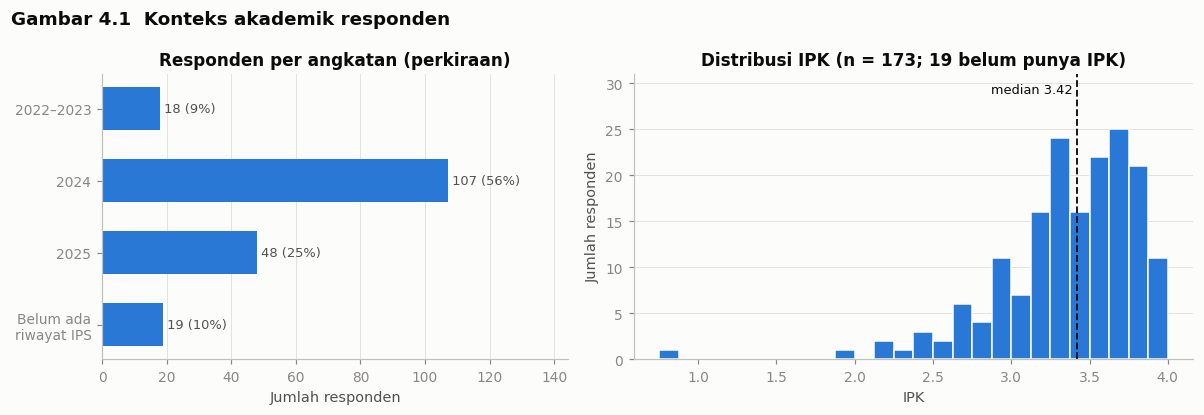

count    173.00
mean       3.36
std        0.45
min        0.87
25%        3.19
50%        3.42
75%        3.67
max        4.00

IPK < 2,00: 2 responden | IPK ≥ 3,50: 79 responden


In [145]:
eda["angkatan_tampil"] = eda["angkatan_perkiraan"].replace({"2022": "2022–2023", "2023": "2022–2023",
                                                            "Belum ada riwayat IPS": "Belum ada\nriwayat IPS"})
urut_akt = ["2022–2023", "2024", "2025", "Belum ada\nriwayat IPS"]
n_akt = eda["angkatan_tampil"].value_counts().reindex(urut_akt)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
bars = ax1.barh(n_akt.index[::-1], n_akt.values[::-1], color=UTAMA, height=0.6)
label_batang(ax1, bars, total=len(eda))
ax1.set_xlim(0, n_akt.max() * 1.35)
ax1.set_title("Responden per angkatan (perkiraan)")
ax1.set_xlabel("Jumlah responden"); ax1.grid(axis="y", visible=False)

ipk = eda["ipk"].dropna()
ax2.hist(ipk, bins=np.arange(0.75, 4.01, 0.125), color=UTAMA, edgecolor=SURF, linewidth=1)
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.18)
ax2.axvline(ipk.median(), color=INK, linewidth=1.2, linestyle="--")
ax2.text(ipk.median() - 0.03, ax2.get_ylim()[1] * 0.97, f"median {ipk.median():.2f}", color=INK, fontsize=8.5,
         va="top", ha="right")
ax2.set_title(f"Distribusi IPK (n = {len(ipk)}; {eda['ipk'].isna().sum()} belum punya IPK)")
ax2.set_xlabel("IPK"); ax2.set_ylabel("Jumlah responden"); ax2.grid(axis="x", visible=False)
fig.suptitle("Gambar 4.1  Konteks akademik responden", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
simpan(fig, "4_1_konteks_akademik")

print(ipk.describe().round(2).to_string())
print("\nIPK < 2,00:", int((ipk < 2).sum()), "responden | IPK ≥ 3,50:", int((ipk >= 3.5).sum()), "responden")

**Interpretasi:**
- **Angkatan:** responden didominasi angkatan **2024 (56%)**, diikuti 2025 (25%), 2022–2023 (9%), dan kelompok tanpa riwayat IPS (10%, kemungkinan mahasiswa baru).
- **IPK:** median **3,42** dengan sebaran miring ke kiri. Sekitar 46% responden ber-IPK ≥ 3,50, dan hanya 2 responden di bawah 2,00.

- **Dapat disimpulkan:**
  - Statistik agregat pada notebook ini sebagian besar mencerminkan mahasiswa angkatan 2024.
  - Variasi IPK relatif sempit di bagian atas, sehingga hubungan apa pun dengan IPK sulit terlihat (*range restriction*).
- **Tidak dapat disimpulkan:**
  - Perbandingan antar-program studi, karena datanya tidak tersedia.
  - Angkatan yang pasti, karena `angkatan_perkiraan` hanya perkiraan dari riwayat IPS.
  - Kelompok kecil tidak ditampilkan terpisah demi menjaga anonimitas.

### 4.3 Distribusi skor/dimensi tiap framework
**Pertanyaan:** bagaimana bentuk sebaran skor tiap dimensi, apakah ada dimensi yang menonjol, dan apakah skor mengumpul di ujung skala (efek plafon)?

Setiap framework punya rentang skor berbeda (VARK 0–16, HM 8–40, FS 4–20, Kolb 6–30), sehingga ditampilkan di panel terpisah dengan sumbu masing-masing. **Membandingkan nilai mentah antar-panel tidak bermakna.**

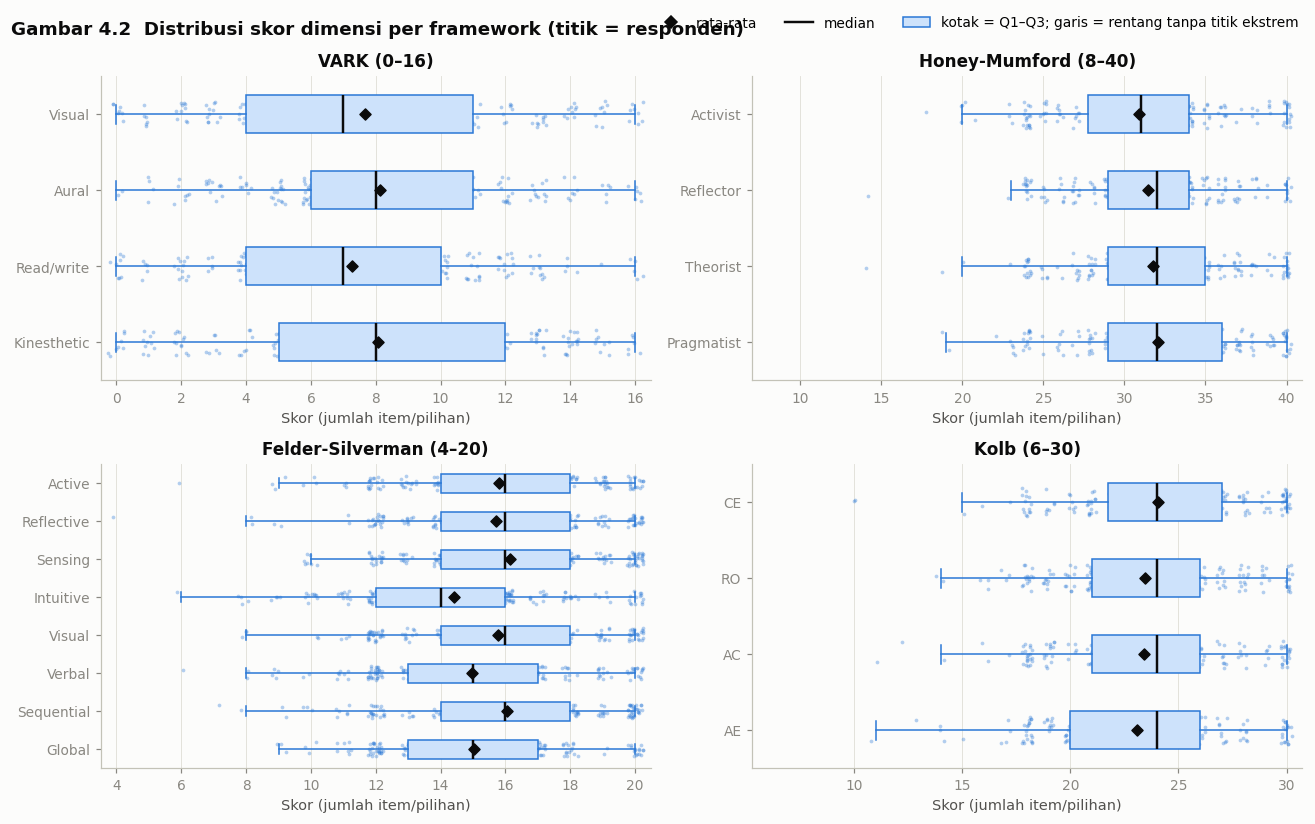

In [146]:
PANEL_SKOR = {
    "VARK (0–16)": (SKOR_VARK, ["Visual", "Aural", "Read/write", "Kinesthetic"], (0, 16)),
    "Honey-Mumford (8–40)": (SKOR_HM, ["Activist", "Reflector", "Theorist", "Pragmatist"], (8, 40)),
    "Felder-Silverman (4–20)": (SKOR_FS, ["Active", "Reflective", "Sensing", "Intuitive",
                                          "Visual", "Verbal", "Sequential", "Global"], (4, 20)),
    "Kolb (6–30)": (SKOR_KOLB, ["CE", "RO", "AC", "AE"], (6, 30)),
}
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (judul, (kol, nama, (lo, hi))) in zip(axes.ravel(), PANEL_SKOR.items()):
    data = [eda[c].astype(float).values for c in kol]
    bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, linewidth=1.6),
                    boxprops=dict(facecolor="#cde2fb", edgecolor=UTAMA, linewidth=1),
                    whiskerprops=dict(color=UTAMA), capprops=dict(color=UTAMA))
    for i, d in enumerate(data, start=1):
        ax.scatter(d + rng.uniform(-0.25, 0.25, len(d)), i + rng.uniform(-0.18, 0.18, len(d)),
                   s=6, color=UTAMA, alpha=0.35, linewidths=0)
        ax.scatter(d.mean(), i, marker="D", s=26, color=INK, zorder=3)
    ax.set_yticks(range(1, len(nama) + 1), nama)
    ax.invert_yaxis()
    ax.set_xlim(lo - (hi - lo) * 0.03, hi + (hi - lo) * 0.03)
    ax.set_title(judul); ax.set_xlabel("Skor (jumlah item/pilihan)"); ax.grid(axis="y", visible=False)
fig.legend(handles=[plt.Line2D([], [], marker="D", color=INK, linestyle="", markersize=6),
                    plt.Line2D([], [], color=INK, linewidth=1.6),
                    plt.Rectangle((0, 0), 1, 1, facecolor="#cde2fb", edgecolor=UTAMA)],
           labels=["rata-rata", "median", "kotak = Q1–Q3; garis = rentang tanpa titik ekstrem"],
           loc="upper right", ncol=3, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Gambar 4.2  Distribusi skor dimensi per framework (titik = responden)", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
simpan(fig, "4_2_distribusi_skor")

In [147]:
def ringkas_skor(kol):
    t = eda[kol].astype(float).agg(["mean", "std", "median", "skew"]).T
    rentang_max = {c: RANGE_SKOR[c][1] for c in kol}
    t["% di skor maksimum"] = [(eda[c] == rentang_max[c]).mean() * 100 for c in kol]
    return t.round(2)

tabel_skor = pd.concat({fw: ringkas_skor(kol) for fw, (kol, _, _) in PANEL_SKOR.items()})
# Uji Friedman: apakah skor antar-dimensi dalam satu framework berbeda (data berpasangan, non-parametrik)
uji_dim = pd.DataFrame({fw: dict(zip(["chi2", "p_value"], stats.friedmanchisquare(*[eda[c].astype(float) for c in kol])))
                        for fw, (kol, _, _) in PANEL_SKOR.items()}).T
uji_dim["p_value"] = uji_dim["p_value"].map(lambda p: f"{p:.2e}" if p < 0.001 else f"{p:.3f}")
display(tabel_skor)
display(uji_dim.round(2))

mean   std  median  skew  % di skor maksimum
VARK (0–16)             skor_vark_v          7.66  4.35     7.0  0.24                4.17
                        skor_vark_a          8.14  3.80     8.0  0.14                3.12
                        skor_vark_r          7.28  3.96     7.0  0.15                2.60
                        skor_vark_k          8.07  4.45     8.0 -0.06                3.12
Honey-Mumford (8–40)    skor_hm_activist    30.92  5.03    31.0 -0.05                7.81
                        skor_hm_reflector   31.45  4.45    32.0 -0.24                5.21
                        skor_hm_theorist    31.78  4.84    32.0 -0.28                8.33
                        skor_hm_pragmatist  32.06  4.92    32.0 -0.25                8.33
Felder-Silverman (4–20) skor_fs_active      15.79  2.74    16.0 -0.50                9.38
                        skor_fs_reflective  15.71  2.76    16.0 -0.57               11.46
                        skor_fs_sensing     16.15  2.72    16.0 -0.33               15.62
                        skor_fs_intuitive   14.42  3.00    14.0 -0.03                7.29
                        skor_fs_visual      15.76  2.78    16.0 -0.33               12.50
                        skor_fs_verbal      14.96  2.89    15.0 -0.14                8.33
                        skor_fs_sequential  16.03  2.89    16.0 -0.58               15.10
                        skor_fs_global      15.03  2.63    15.0  0.07                8.33
Kolb (6–30)             skor_kolb_ce        24.03  3.94    24.0 -0.44               11.98
                        skor_kolb_ro        23.45  3.74    24.0 -0.09                6.77
                        skor_kolb_ac        23.41  3.89    24.0 -0.24                9.38
                        skor_kolb_ae        23.06  3.98    24.0 -0.18                9.38

,chi2,p_value
VARK (0–16),3.91,0.272
Honey-Mumford (8–40),23.52,3.15e-05
Felder-Silverman (4–20),97.09,4.30e-18
Kolb (6–30),16.26,0.001


**Interpretasi:**
- **VARK:** keempat modalitas memiliki rata-rata yang mirip (7,3–8,1 dari 16) dengan sebaran sangat lebar (0–16). Uji Friedman **tidak** menemukan perbedaan antar-modalitas (p = 0,27). Pada tingkat kelompok, tidak ada modalitas yang dominan, dan preferensi sangat bervariasi antar-individu.
- **HM, FS, Kolb:** skor menumpuk di separuh atas skala. Median HM 31–32 dari 40, FS 14–16 dari 20, Kolb 24 dari 30. Kemiringan (*skew*) umumnya negatif, dan 5–16% responden mencapai skor maksimum (**efek plafon**).
- Uji Friedman signifikan untuk HM, FS, dan Kolb, tetapi **selisih mediannya kecil** (1–2 poin). Selisih terbesar ada di FS: Sensing (16) lebih tinggi dari Intuitive (14).

- **Dapat disimpulkan:**
  - Responden cenderung menyetujui hampir semua pernyataan.
  - Perbedaan antar-dimensi dalam satu framework ada tetapi tipis.
- **Tidak dapat disimpulkan:**
  - Signifikan dengan n = 192 tidak berarti perbedaannya bermakna secara praktis.
  - Skor antar-panel tidak dapat dibandingkan langsung karena rentang dan jumlah itemnya berbeda.

#### 4.3.1 Indeks bipolar: ke kutub mana responden condong?
**Pertanyaan:** pada dimensi yang bersifat dua kutub (FS) dan sumbu Kolb, apakah responden condong ke salah satu sisi atau berada di tengah?

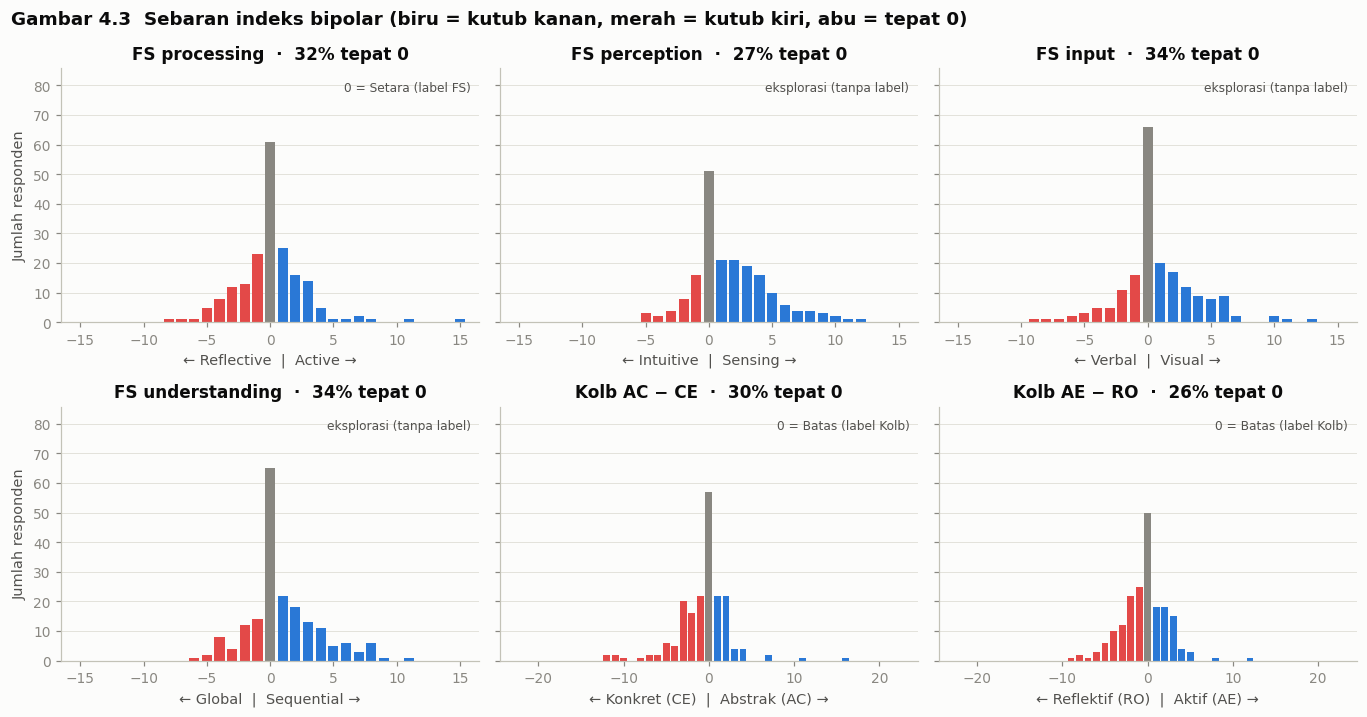

In [148]:
PANEL_IDX = {
    "indeks_fs_act_ref": ("FS processing", "← Reflective  |  Active →"),
    "indeks_fs_sen_int": ("FS perception", "← Intuitive  |  Sensing →"),
    "indeks_fs_vis_ver": ("FS input", "← Verbal  |  Visual →"),
    "indeks_fs_seq_glo": ("FS understanding", "← Global  |  Sequential →"),
    "indeks_kolb_ac_ce": ("Kolb AC − CE", "← Konkret (CE)  |  Abstrak (AC) →"),
    "indeks_kolb_ae_ro": ("Kolb AE − RO", "← Reflektif (RO)  |  Aktif (AE) →"),
}
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.6), sharey=True)
Y_MAX = max(eda[c].value_counts().max() for c in PANEL_IDX) * 1.3
for ax, (c, (judul, xlabel)) in zip(axes.ravel(), PANEL_IDX.items()):
    ax.set_ylim(0, Y_MAX)
    v = eda[c].astype(int)
    hitung = v.value_counts().sort_index()
    warna = [MUTED if x == 0 else ("#2a78d6" if x > 0 else "#e34948") for x in hitung.index]
    ax.bar(hitung.index, hitung.values, color=warna, width=0.8)
    ax.set_xlim(*((-16.5, 16.5) if c.startswith("indeks_fs") else (-24.5, 24.5)))
    keterangan_nol = {"indeks_fs_act_ref": "0 = Setara (label FS)", "indeks_kolb_ac_ce": "0 = Batas (label Kolb)",
                      "indeks_kolb_ae_ro": "0 = Batas (label Kolb)"}.get(c, "eksplorasi (tanpa label)")
    ax.text(0.98, 0.95, keterangan_nol, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK2)
    pct0 = (v == 0).mean() * 100
    ax.set_title(f"{judul}  ·  {pct0:.0f}% tepat 0")
    ax.set_xlabel(xlabel); ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Jumlah responden")
fig.suptitle("Gambar 4.3  Sebaran indeks bipolar (biru = kutub kanan, merah = kutub kiri, abu = tepat 0)",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
simpan(fig, "4_3_indeks_bipolar")

**Interpretasi:**
- Semua indeks **mengumpul di sekitar 0**: 26–34% responden bernilai tepat 0.
- Kecondongan paling jelas ada di FS *perception* ke arah **Sensing** (rata-rata +1,7). Indeks lain hampir simetris. Kedua sumbu Kolb sedikit condong ke sisi konkret dan reflektif.
- Nilai 0 langsung menentukan label menurut aturan dosen:
  - **32% responden bernilai 0 pada Active–Reflective**, sehingga 61 responden berlabel `Setara`.
  - **Pada Kolb, d1 = 0 (30%) atau d2 = 0 (26%)**, sehingga 70 responden (36,5%) berlabel `Batas`. Ini termasuk seluruh 15 responden straightlining.

- **Dapat disimpulkan:** banyaknya skor seimbang membuat kategori teknis `Setara` dan `Batas` menjadi kelompok besar (4.4).
- **Tidak dapat disimpulkan:** bahwa mahasiswa "tidak punya preferensi". Nilai 0 bisa muncul karena:
  - kecenderungan menyetujui kedua kutub (4.5.2);
  - skor jumlah yang berupa bilangan bulat dari hanya 4–6 item per kutub, sehingga hasil seri mudah terjadi.

### 4.4 Distribusi label/profil dan class imbalance
**Pertanyaan:** bagaimana proporsi tiap kategori label, dan jika label dijadikan target klasifikasi di tahap berikutnya, seberapa besar ketidakseimbangan kelasnya?

Ukuran ketidakseimbangan yang dipakai:
- **% kelas mayoritas**: porsi kategori terbesar.
- **Imbalance ratio (IR)**: n kelas terbesar ÷ n kelas terkecil.
- **n kelas terkecil**: jika kurang dari ±10, kelas itu terlalu kecil untuk dipelajari atau dievaluasi secara andal.

In [149]:
def ringkas_label(s):
    vc = s.value_counts()
    return {"n_kelas": len(vc), "kelas_mayoritas": vc.index[0], "% mayoritas": round(vc.iloc[0] / vc.sum() * 100, 1),
            "kelas_terkecil": vc.index[-1], "n_terkecil": int(vc.iloc[-1]), "imbalance_ratio": round(vc.iloc[0] / vc.iloc[-1], 1)}

tabel_imbalance = pd.DataFrame({c: ringkas_label(eda[c]) for c in LABEL_UTAMA}).T
tabel_imbalance["% kategori teknis"] = [round(eda[c].isin(TEKNIS).mean() * 100, 1) for c in LABEL_UTAMA]
tabel_imbalance

,n_kelas,kelas_mayoritas,% mayoritas,kelas_terkecil,n_terkecil,imbalance_ratio,% kategori teknis
label_vark,5,Kinesthetic,26.6,Seri,30,1.7,15.6
label_hm,5,Seri,33.3,Activist,18,3.6,33.3
label_fs_act_ref,3,Active,34.9,Setara,61,1.1,31.8
label_kolb,5,Batas,36.5,AC_AE,18,3.9,36.5


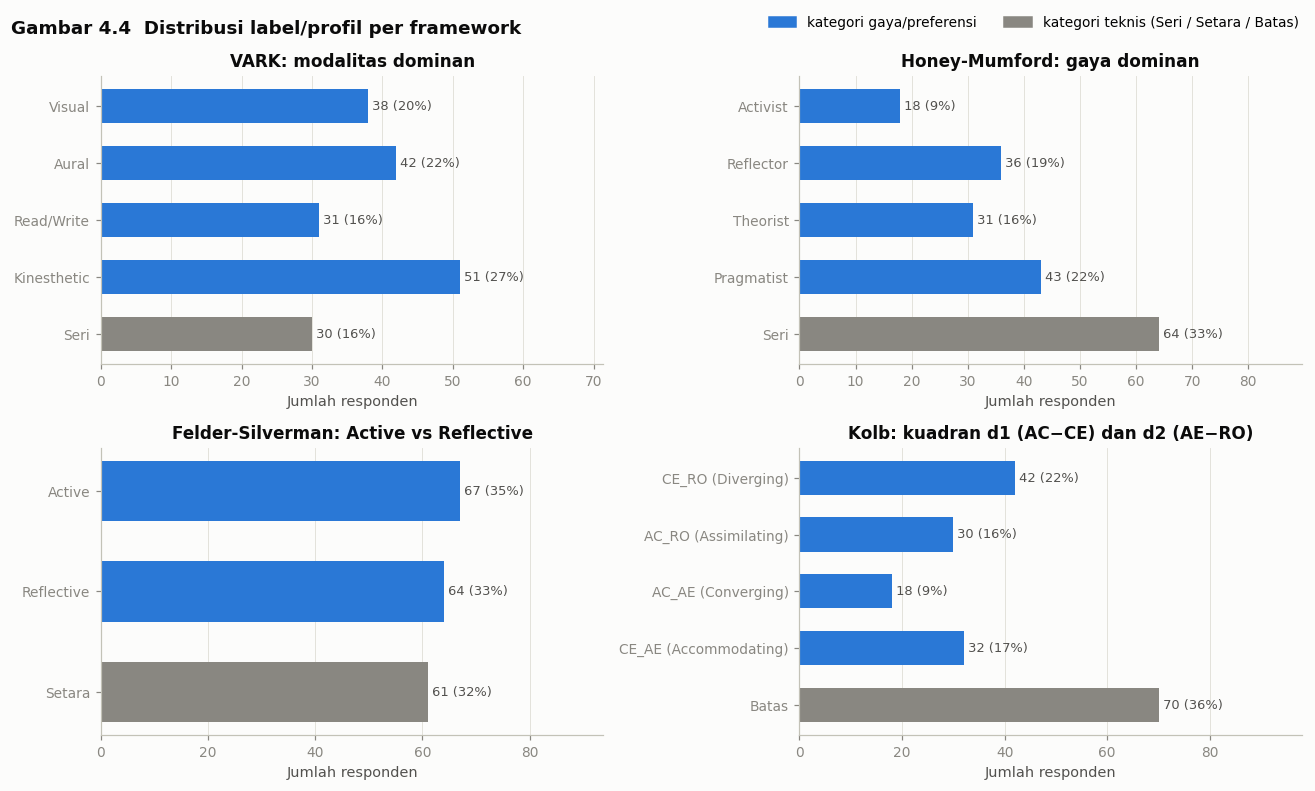

In [150]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
JUDUL_LABEL = {"label_vark": "VARK: modalitas dominan", "label_hm": "Honey-Mumford: gaya dominan",
               "label_fs_act_ref": "Felder-Silverman: Active vs Reflective",
               "label_kolb": "Kolb: kuadran d1 (AC−CE) dan d2 (AE−RO)"}
for ax, c in zip(axes.ravel(), LABEL_UTAMA):
    urutan = KATEGORI_LABEL[c]
    vc = eda[c].value_counts().reindex(urutan).fillna(0)
    nama_y = [f"{k} ({MAKNA_KOLB[k]})" if c == "label_kolb" and k != "Batas" else k for k in urutan]
    bars = ax.barh(range(len(vc)), vc.values, height=0.6,
                   color=[MUTED if k in TEKNIS else UTAMA for k in urutan])
    ax.set_yticks(range(len(vc)), nama_y); ax.invert_yaxis()
    label_batang(ax, bars, total=len(eda))
    ax.set_xlim(0, vc.max() * 1.4); ax.set_title(JUDUL_LABEL[c]); ax.set_xlabel("Jumlah responden")
    ax.grid(axis="y", visible=False)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=UTAMA), plt.Rectangle((0, 0), 1, 1, color=MUTED)],
           labels=["kategori gaya/preferensi", "kategori teknis (Seri / Setara / Batas)"],
           loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Gambar 4.4  Distribusi label/profil per framework", x=0.01, ha="left", fontsize=12,
             fontweight="bold", color=INK)
fig.tight_layout()
simpan(fig, "4_4_distribusi_label")

**Interpretasi class imbalance** (label mengikuti aturan dosen):

| Label | Temuan | Catatan untuk tahap klasifikasi |
|---|---|---|
| `label_vark` | Kinesthetic terbanyak (27%), `Seri` 16%, IR = 1,7 | **Paling seimbang**; kelas terkecil masih n = 30 |
| `label_hm` | `Seri` terbanyak (33%); Activist paling sedikit (9%, n = 18); IR = 3,6 | Kategori teknis menjadi kelas mayoritas |
| `label_fs_act_ref` | Active 35%, Reflective 33%, `Setara` 32%; IR = 1,1 | Seimbang, tetapi hampir sepertiga responden `Setara` |
| `label_kolb` | `Batas` terbanyak (36,5%); AC_AE paling sedikit (9%, n = 18); IR = 3,9 | Kategori teknis menjadi kelas mayoritas |

- **Dapat disimpulkan:**
  - Tidak ada ketidakseimbangan ekstrem (IR ≤ 3,9), tetapi **kategori teknis (`Seri`/`Setara`/`Batas`) sangat besar**: 16–37% responden.
  - Kelas terkecil (n = 18) hanya akan menyisakan sekitar 3–4 contoh di test set 20%. Jika label dipakai sebagai target, pembagian data perlu **stratifikasi**, dan evaluasi perlu memakai **macro-F1** selain akurasi.
- **Tidak dapat disimpulkan:** proporsi label sebagai prevalensi gaya belajar di populasi mahasiswa. Kategori teknis juga bukan gaya belajar. Panduan dosen menegaskan `Seri`, `Setara`, dan `Batas` bukan tipe tambahan.

### 4.5 Missingness, nilai ekstrem, dan pola data yang berisiko
#### 4.5.1 Pola missing pada IPS
**Pertanyaan:** apakah IPS yang kosong terjadi acak, atau mengikuti struktur tertentu? Ini menentukan boleh tidaknya diimputasi.

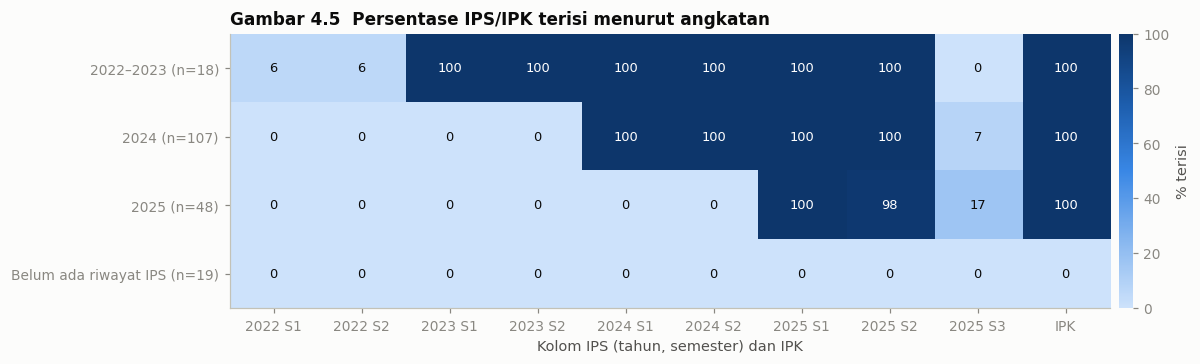

In [151]:
terisi = eda.groupby("angkatan_tampil")[IPS_COLS + ["ipk"]].apply(lambda g: g.notna().mean() * 100).reindex(urut_akt)
terisi.columns = [c.replace("ips_", "").replace("_s", " S") if c != "ipk" else "IPK" for c in terisi.columns]

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(terisi.values, cmap=CMAP_SEQ, vmin=0, vmax=100, aspect="auto")
for i in range(terisi.shape[0]):
    for j in range(terisi.shape[1]):
        v = terisi.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="#ffffff" if v > 55 else INK)
ax.set_xticks(range(terisi.shape[1]), terisi.columns, rotation=0)
ax.set_yticks(range(terisi.shape[0]), [f"{a.replace(chr(10), ' ')} (n={n_akt[a]})" for a in terisi.index])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("% terisi"); cb.outline.set_visible(False)
ax.set_xlabel("Kolom IPS (tahun, semester) dan IPK")
ax.set_title("Gambar 4.5  Persentase IPS/IPK terisi menurut angkatan", loc="left")
fig.tight_layout()
simpan(fig, "4_5_pola_missing_ips")

**Interpretasi:** pola missing IPS berbentuk **tangga** yang rapi. Setiap angkatan terisi 100% mulai semester pertamanya, dan kosong sebelumnya.
- Pengecualian kecil: 1 responden 2025 tanpa IPS 2025 S2 (98%).
- Semester pendek 2025 S3 hanya diisi 7–17%.
- Kelompok tanpa riwayat IPS kosong di semua kolom, termasuk IPK.

- **Dapat disimpulkan:**
  - Missing ini **struktural**, ditentukan oleh angkatan, bukan acak. Imputasi akan menciptakan nilai untuk semester yang tidak pernah dijalani.
  - Analisis yang memakai IPK hanya berlaku untuk 173 responden dan **tidak mewakili 19 responden terbaru**.
- **Tidak dapat disimpulkan:** perbandingan IPS antar-semester yang sama untuk semua responden, karena setiap angkatan menempati semester berbeda.

#### 4.5.2 Gaya menjawab Likert (kecenderungan setuju)
**Pertanyaan:** bagaimana responden memakai skala 1–5? Jika jawaban terkonsentrasi di "setuju", skor semua dimensi akan ikut tinggi bersamaan.

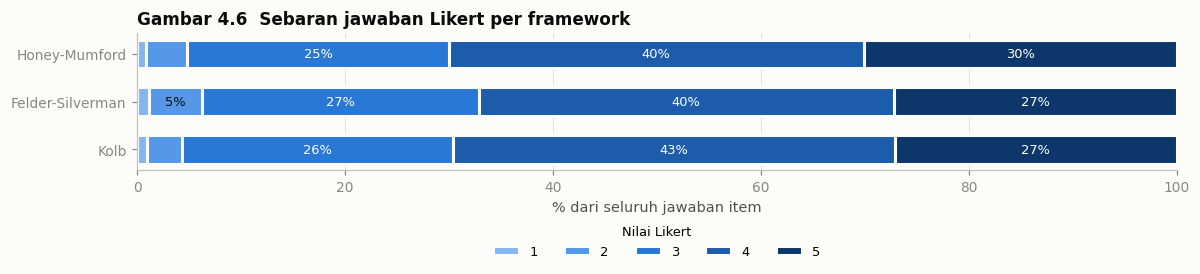

Korelasi Spearman skor dimensi dengan rata-rata semua jawaban Likert responden:
min    0.60
50%    0.79
max    0.85


In [152]:
FW_ITEM = {"Honey-Mumford": HM_COLS, "Felder-Silverman": FS_COLS, "Kolb": KOLB_COLS}
porsi_jawab = pd.DataFrame({fw: eda[kol].stack().value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0) * 100
                            for fw, kol in FW_ITEM.items()}).T

fig, ax = plt.subplots(figsize=(11, 2.9))
kiri = np.zeros(len(porsi_jawab))
for nilai, warna in zip([1, 2, 3, 4, 5], ORDINAL5):
    v = porsi_jawab[nilai].values
    ax.barh(porsi_jawab.index, v, left=kiri, color=warna, edgecolor=SURF, linewidth=2, height=0.6, label=str(nilai))
    for i, (l, w) in enumerate(zip(kiri, v)):
        if w >= 5:
            ax.text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=8.5,
                    color=INK if nilai <= 2 else "#ffffff")
    kiri += v
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% dari seluruh jawaban item"); ax.grid(axis="y", visible=False)
ax.legend(title="Nilai Likert", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.32), fontsize=8.5, title_fontsize=8.5)
ax.set_title("Gambar 4.6  Sebaran jawaban Likert per framework", loc="left")
fig.tight_layout()
simpan(fig, "4_6_gaya_menjawab")

eda["rata2_likert"] = eda[HM_COLS + FS_COLS + KOLB_COLS].astype(float).mean(axis=1)
r_acq = eda[SKOR_HM + SKOR_FS + SKOR_KOLB].corrwith(eda["rata2_likert"], method="spearman")
print("Korelasi Spearman skor dimensi dengan rata-rata semua jawaban Likert responden:")
print(r_acq.describe()[["min", "50%", "max"]].round(2).to_string())

**Interpretasi:**
- Nilai 1–2 hanya dipakai pada <7% jawaban, sedangkan nilai 4–5 mencapai **67–70%** di ketiga framework.
- Skor setiap dimensi berkorelasi **ρ = 0,60–0,85** dengan rata-rata seluruh jawaban Likert responden. Responden yang "suka menjawab setuju" akan mendapat skor tinggi di **semua** dimensi.

- **Dapat disimpulkan:**
  - Ada **gaya menjawab umum** (*acquiescence/response style*) yang kuat. Gaya ini menjelaskan efek plafon (4.3), banyaknya nilai 0 pada indeks bipolar, dan korelasi tinggi antar-dimensi (4.6).
  - Untuk analisis lanjutan, perlu dipertimbangkan skor yang dikoreksi terhadap rata-rata responden, misalnya skor terpusat/ipsatif, atau model yang memperhitungkan gaya menjawab.
- **Tidak dapat disimpulkan:** apakah tingginya skor mencerminkan preferensi nyata atau hanya gaya menjawab. Data ini tidak bisa memisahkan keduanya secara pasti.

#### 4.5.3 Nilai ekstrem dan responden ber-flag: seberapa besar pengaruhnya?
**Pertanyaan:** apakah responden yang ditandai di Tahap 2 mengubah gambaran distribusi skor dan label?

In [153]:
print("Jumlah responden ber-flag:", eda[FLAG_COLS].sum().to_dict())
banding = pd.DataFrame({
    "median semua": eda[SKOR_HM + SKOR_FS + SKOR_KOLB].median(),
    "median tanpa straightlining": eda.loc[~eda["flag_straightline"], SKOR_HM + SKOR_FS + SKOR_KOLB].median(),
})
banding["selisih"] = banding.iloc[:, 1] - banding.iloc[:, 0]
print("\nSkor dimensi dengan median yang berubah jika responden straightlining dikeluarkan:")
display(banding[banding["selisih"] != 0])

sl = eda["flag_straightline"]
print("Label responden straightlining:", {c: eda.loc[sl, c].value_counts().to_dict() for c in LABEL_UTAMA})
label_banding = pd.concat({c: pd.DataFrame({
    "% semua": eda[c].value_counts(normalize=True) * 100,
    "% tanpa straightlining": eda.loc[~sl, c].value_counts(normalize=True) * 100,
}).reindex(KATEGORI_LABEL[c]).fillna(0).round(1) for c in LABEL_UTAMA})
print("Distribusi label dengan dan tanpa responden straightlining:")
display(label_banding)

ekstrem = eda[eda["flag_akademik_ekstrem"]]
print(f"IPK median responden flag_akademik_ekstrem: {ekstrem['ipk'].median():.2f} (n={len(ekstrem)}) "
      f"vs lainnya: {eda.loc[~eda['flag_akademik_ekstrem'], 'ipk'].median():.2f}")

Jumlah responden ber-flag: {'flag_akademik_ekstrem': 10, 'flag_straightline': 15, 'flag_vark_semua_opsi': 1}

Skor dimensi dengan median yang berubah jika responden straightlining dikeluarkan:


,median semua,median tanpa straightlining,selisih
skor_kolb_ae,24.0,23.0,-1.0


Label responden straightlining: {'label_vark': {'Aural': 6, 'Seri': 6, 'Read/Write': 2, 'Kinesthetic': 1}, 'label_hm': {'Seri': 15}, 'label_fs_act_ref': {'Setara': 15}, 'label_kolb': {'Batas': 15}}
Distribusi label dengan dan tanpa responden straightlining:


% semua  % tanpa straightlining
label_vark       Visual          19.8                    21.5
                 Aural           21.9                    20.3
                 Read/Write      16.1                    16.4
                 Kinesthetic     26.6                    28.2
                 Seri            15.6                    13.6
label_hm         Activist         9.4                    10.2
                 Reflector       18.8                    20.3
                 Theorist        16.1                    17.5
                 Pragmatist      22.4                    24.3
                 Seri            33.3                    27.7
label_fs_act_ref Active          34.9                    37.9
                 Reflective      33.3                    36.2
                 Setara          31.8                    26.0
label_kolb       CE_RO           21.9                    23.7
                 AC_RO           15.6                    16.9
                 AC_AE            9.4                    10.2
                 CE_AE           16.7                    18.1
                 Batas           36.5                    31.1

IPK median responden flag_akademik_ekstrem: 2.33 (n=10) vs lainnya: 3.46


**Interpretasi:**
- **Straightlining (15 responden):** seluruhnya otomatis berlabel `Seri` (HM), `Setara` (FS), dan `Batas` (Kolb), karena semua skornya sama. Label VARK mereka tetap bervariasi, karena VARK berformat multi-select.
- Mengeluarkan mereka hanya menurunkan kategori teknis sekitar 5–6 poin persen: HM `Seri` 33,3% → 27,7%, FS `Setara` 31,8% → 26,0%, Kolb `Batas` 36,5% → 31,1%. Jadi kategori teknis **sebagian besar berasal dari skor seri pada responden biasa**, bukan hanya dari straightlining.
- Pada skor dimensi, hanya 1 median yang bergeser (Kolb AE 24 → 23).
- **Ekstrem akademik (10 responden):** median IPK mereka 2,33 dibanding 3,46 untuk responden lain. Nilai ini **valid**, sehingga tetap dipertahankan. Metode berbasis peringkat di 4.6 relatif tahan terhadap nilai ekstrem.

- **Dapat disimpulkan:** responden ber-flag tidak mengubah distribusi skor, tetapi menambah porsi kategori teknis pada label.
- **Rekomendasi:** distribusi label dilaporkan dalam dua versi, dengan dan tanpa responden straightlining (analisis sensitivitas).

### 4.6 Korelasi dan asosiasi antarvariabel
Metode dipilih sesuai tipe data:

| Pasangan tipe data | Metode | Alasan |
|---|---|---|
| Numerik/ordinal × numerik/ordinal (skor, IPK) | **Spearman ρ** | Skor berasal dari item Likert (ordinal) dan tidak berdistribusi normal; Spearman hanya mengasumsikan hubungan monoton |
| Nominal × nominal (label, angkatan) | **Cramér's V** (dengan koreksi bias) dari uji chi-square | Label adalah kategori tanpa urutan, sehingga korelasi numerik tidak sah |
| Nominal × numerik (label × IPK) | **Kruskal-Wallis** + ukuran efek ε² | Membandingkan sebaran numerik antar-kelompok tanpa asumsi normal |

Karena banyak uji dilakukan sekaligus, p-value dikoreksi dengan metode **Holm** untuk mengurangi temuan "signifikan" yang kebetulan.

In [154]:
def holm(p):
    p = np.asarray(p, float); n = len(p); urut = np.argsort(p)
    adj = np.empty(n); kum = 0
    for k, i in enumerate(urut):
        kum = max(kum, (n - k) * p[i]); adj[i] = min(kum, 1)
    return adj

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1)))
    return v, p, (exp < 5).mean() * 100, int(n)

#### 4.6.1 Korelasi antarskor (Spearman)
**Pertanyaan:** dimensi mana yang bergerak bersama, baik di dalam maupun antar-framework?

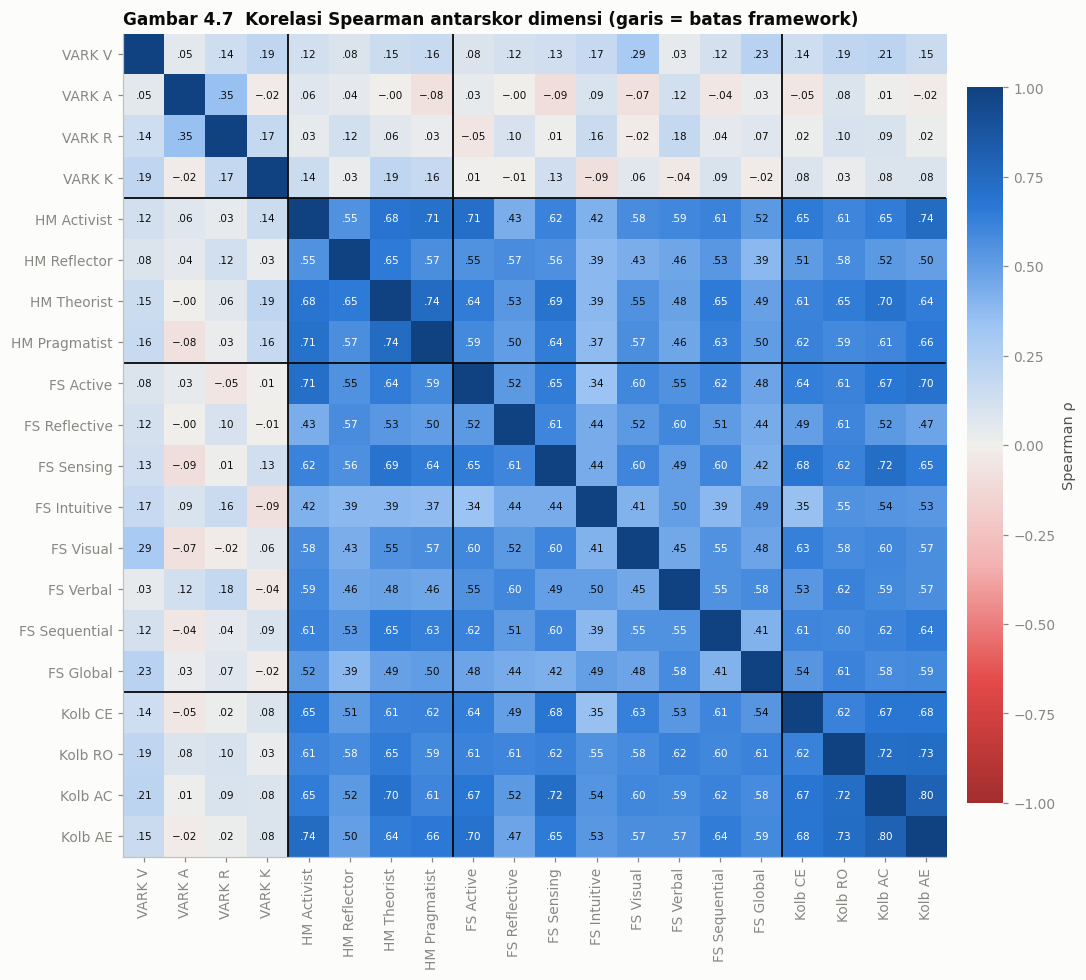

,VARK,HM,FS,Kolb
rata-rata ρ,,,,
VARK,0.15,0.08,0.06,0.08
HM,0.08,0.65,0.53,0.61
FS,0.06,0.53,0.51,0.59
Kolb,0.08,0.61,0.59,0.70


In [155]:
SKOR_KORR = SKOR_VARK + SKOR_HM + SKOR_FS + SKOR_KOLB
PREF = {"vark": "VARK", "hm": "HM", "fs": "FS", "kolb": "Kolb"}
nama_pendek = {}
for c in SKOR_KORR:
    _, fw, dim = c.split("_", 2)
    nama_pendek[c] = f"{PREF[fw]} {dim.upper() if fw in ('vark', 'kolb') else dim.title()}"
rho = eda[SKOR_KORR].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(rho.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
for i in range(len(rho)):
    for j in range(len(rho)):
        if i != j:
            v = rho.values[i, j]
            ax.text(j, i, f"{v:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center", fontsize=6.8,
                    color="#ffffff" if abs(v) > 0.55 else INK)
batas = np.cumsum([len(SKOR_VARK), len(SKOR_HM), len(SKOR_FS)]) - 0.5
for b in batas:
    ax.axhline(b, color=INK, linewidth=1.2); ax.axvline(b, color=INK, linewidth=1.2)
lbl = [nama_pendek[c] for c in SKOR_KORR]
ax.set_xticks(range(len(lbl)), lbl, rotation=90); ax.set_yticks(range(len(lbl)), lbl); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Gambar 4.7  Korelasi Spearman antarskor dimensi (garis = batas framework)", loc="left")
fig.tight_layout()
simpan(fig, "4_7_korelasi_skor")

def rata_blok(a, b):
    m = rho.loc[a, b].values
    return m[~np.eye(len(a), dtype=bool)].mean() if a == b else m.mean()
BLOK = {"VARK": SKOR_VARK, "HM": SKOR_HM, "FS": SKOR_FS, "Kolb": SKOR_KOLB}
pd.DataFrame({x: {y: rata_blok(BLOK[x], BLOK[y]) for y in BLOK} for x in BLOK}).round(2).rename_axis("rata-rata ρ")

**Interpretasi:**
- **HM, FS, dan Kolb saling berkorelasi tinggi**, baik di dalam framework (rata-rata ρ 0,51–0,70) maupun antar-framework (0,53–0,61).
- Dimensi yang secara teori **berlawanan** juga berkorelasi positif kuat. Contohnya FS Active–Reflective ρ = 0,52, Kolb AC–CE ρ = 0,67, dan Kolb AE–RO ρ = 0,73. Ini konsisten dengan gaya menjawab umum di 4.5.2.
- **VARK hampir independen** dari ketiga framework lain (rata-rata ρ 0,06–0,08), dan antar-modalitas VARK pun lemah (0,15). Formatnya multi-select, sehingga tidak terpengaruh kecenderungan setuju.

- **Dapat disimpulkan:** korelasi mentah antar-skor Likert didominasi faktor umum, sehingga **tidak bisa langsung dibaca** sebagai kemiripan konstruk.
- **Tidak dapat disimpulkan:** hubungan sebab-akibat, atau bahwa framework-framework ini "mengukur hal yang sama". Lihat 4.7 untuk analisis setelah gaya menjawab dikendalikan.

#### 4.6.2 Skor dimensi × IPK (Spearman, koreksi Holm)
**Pertanyaan:** apakah ada dimensi gaya belajar yang berhubungan dengan prestasi akademik? Hanya responden yang punya IPK yang dipakai.

In [156]:
baris = []
for c in SKOR_KORR:
    x = eda[[c, "ipk"]].dropna()
    r, p = stats.spearmanr(x[c].astype(float), x["ipk"])
    baris.append((nama_pendek[c], len(x), r, p))
skor_ipk = pd.DataFrame(baris, columns=["skor", "n", "rho", "p"])
skor_ipk["p_holm"] = holm(skor_ipk["p"])
skor_ipk["signifikan (Holm, α=0,05)"] = skor_ipk["p_holm"] < 0.05
skor_ipk.sort_values("rho", key=abs, ascending=False).head(6).round(3)

,skor,n,rho,p,p_holm,"signifikan (Holm, α=0,05)"
9,FS Reflective,173,0.214,0.005,0.094,False
1,VARK A,173,0.206,0.006,0.122,False
4,HM Activist,173,0.195,0.010,0.182,False
10,FS Sensing,173,0.181,0.017,0.293,False
8,FS Active,173,0.179,0.019,0.297,False
13,FS Verbal,173,0.176,0.020,0.307,False


**Interpretasi:**
- Korelasi terkuat antara skor dimensi dan IPK hanya **ρ ≈ 0,18–0,21** (FS Reflective, VARK A, HM Activist), yang tergolong lemah.
- **Tidak ada satu pun yang signifikan setelah koreksi Holm** atas 20 uji.

- **Dapat disimpulkan:** dalam sampel ini, tidak ada bukti yang kuat bahwa skor gaya belajar berhubungan dengan IPK.
- **Tidak dapat disimpulkan:**
  - Bahwa gaya belajar tidak berpengaruh pada prestasi. Variasi IPK sempit (4.2), n = 173, dan korelasi tidak menunjukkan sebab-akibat.
  - p-value mentah < 0,05 pada beberapa skor **tidak boleh** dilaporkan sebagai temuan tanpa koreksi uji berganda.

#### 4.6.3 Asosiasi antar-label dan dengan konteks (Cramér's V; Kruskal-Wallis)
**Pertanyaan:** apakah label suatu framework berkaitan dengan label framework lain, dengan angkatan, atau dengan IPK?

In [157]:
# Antar-framework: kategori teknis (Seri/Setara/Batas) dikeluarkan, karena responden straightlining otomatis
# masuk kategori teknis di semua framework sekaligus dan akan menciptakan asosiasi semu.
pasangan = [
    ("label_kolb", "label_hm"), ("label_kolb", "label_vark"), ("label_vark", "label_hm"),
    ("label_vark", "angkatan"), ("label_hm", "angkatan"), ("label_kolb", "angkatan"),
]
kol_label = {c: eda[c].where(~eda[c].isin(TEKNIS)) for c in ["label_kolb", "label_hm", "label_vark"]}
kol_label["angkatan"] = eda["angkatan_tampil"].where(eda["angkatan_tampil"] != "Belum ada\nriwayat IPS")
hasil_v = []
for a, b in pasangan:
    x = pd.concat([kol_label[a], kol_label[b]], axis=1).dropna()
    v, p, pct_kecil, n = cramers_v(x.iloc[:, 0], x.iloc[:, 1])
    hasil_v.append((a, b, n, v, p, pct_kecil))
tabel_v = pd.DataFrame(hasil_v, columns=["variabel_1", "variabel_2", "n", "cramers_v", "p", "% sel expected < 5"])
tabel_v["p_holm"] = holm(tabel_v["p"])
display(tabel_v.round(3))

baris = []
for c in ["label_vark", "label_hm", "label_fs_act_ref", "label_kolb"]:
    x = eda[[c, "ipk"]].dropna()
    grup = [g["ipk"].values for _, g in x.groupby(c)]
    H, p = stats.kruskal(*grup)
    eps2 = (H - len(grup) + 1) / (len(x) - len(grup))
    baris.append((c, len(x), len(grup), H, p, max(eps2, 0)))
tabel_kw = pd.DataFrame(baris, columns=["label", "n", "n_kelompok", "H", "p", "epsilon2"])
tabel_kw["p_holm"] = holm(tabel_kw["p"])
display(tabel_kw.round(3))
for c in tabel_kw.loc[tabel_kw["p_holm"] < 0.05, "label"]:
    print(f"\nIPK per kelompok {c}:")
    print(eda.groupby(c)["ipk"].agg(["count", "median"]).round(2).sort_values("median").to_string())

,variabel_1,variabel_2,n,cramers_v,p,% sel expected < 5,p_holm
0,label_kolb,label_hm,95,0.000,0.869,43.750,1.000
1,label_kolb,label_vark,99,0.000,0.544,50.000,1.000
2,label_vark,label_hm,109,0.094,0.220,25.000,1.000
3,label_vark,angkatan,149,0.075,0.260,33.333,1.000
4,label_hm,angkatan,117,0.212,0.012,33.333,0.072
5,label_kolb,angkatan,109,0.000,0.421,41.667,1.000


,label,n,n_kelompok,H,p,epsilon2,p_holm
0,label_vark,173,5,18.206,0.001,0.085,0.004
1,label_hm,173,5,5.304,0.258,0.008,0.773
2,label_fs_act_ref,173,3,1.103,0.576,0.000,1.000
3,label_kolb,173,5,1.715,0.788,0.000,1.000



IPK per kelompok label_vark:
             count  median
label_vark                
Kinesthetic     48    3.30
Read/Write      30    3.34
Visual          33    3.37
Aural           38    3.47
Seri            24    3.68


**Interpretasi:**

**Cramér's V antar-label:**
- Kategori teknis dikeluarkan dulu. Tanpa itu, responden straightlining yang jatuh ke `Seri`/`Setara`/`Batas` di semua framework sekaligus akan menciptakan asosiasi semu.
- Hasilnya, label antar-framework **praktis tidak berkaitan**: Kolb × HM V = 0,00, Kolb × VARK V = 0,00, VARK × HM V = 0,09.

**Label × angkatan:**
- Hanya HM × angkatan yang sedikit menonjol (V = 0,21, p = 0,012), tetapi **tidak signifikan setelah koreksi Holm** (p = 0,07).
- Sebagian sel frekuensinya kecil (33–50% sel expected < 5), sehingga hasil chi-square perlu dibaca hati-hati.

**Kruskal-Wallis IPK per label:**
- IPK hanya berbeda antar-kelompok `label_vark` (ε² = 0,085; p Holm = 0,004). Median tertinggi ada pada kelompok `Seri` (3,68), terendah pada Kinesthetic (3,30).
- Tidak ada perbedaan IPK menurut label HM, FS, atau Kolb.

- **Dapat disimpulkan:** label empat framework saling independen dan tidak berbeda menurut angkatan.
- **Tidak dapat disimpulkan:** bahwa modalitas VARK tertentu menyebabkan IPK lebih tinggi atau rendah. Efeknya kecil, bersifat eksploratif, dan kelompok `Seri` adalah kategori teknis, bukan gaya belajar.

### 4.7 Kesesuaian dan perbedaan antar-framework
Keempat framework **tidak mengukur konstruk yang identik**: VARK mengukur preferensi modalitas informasi, Kolb dan Honey-Mumford mengukur siklus belajar dari pengalaman, sedangkan Felder-Silverman mengukur empat dimensi terpisah. Namun beberapa dimensi berkaitan secara teori. Honey-Mumford sendiri dikembangkan dari siklus Kolb, dan dimensi aktif/reflektif muncul di tiga framework.

**Pertanyaan:** apakah dimensi yang secara teori berkaitan memang berkorelasi **lebih kuat** dibanding pasangan yang tidak berkaitan?

Karena 4.5.2 menunjukkan kecenderungan setuju yang kuat, korelasi ditampilkan dua versi:
1. **Mentah** (Spearman).
2. **Parsial**: mengendalikan rata-rata jawaban Likert responden. Peringkat kedua skor diregresikan terhadap peringkat rata-rata Likert, lalu residunya dikorelasikan.

Versi parsial membantu memisahkan kemiripan isi dari sekadar kecenderungan menjawab tinggi. Pasangan dengan VARK tidak dikoreksi, karena VARK berformat multi-select, bukan Likert.

In [158]:
def spearman_parsial(a, b, z):
    ra, rb, rz = (s.astype(float).rank() for s in (a, b, z))
    res = lambda y: y - np.polyval(np.polyfit(rz, y, 1), rz)
    return stats.pearsonr(res(ra), res(rb))[0]

PASANGAN_TEORI = [
    ("skor_kolb_ae", "skor_hm_activist", "Kolb AE ↔ HM Activist"),
    ("skor_kolb_ae", "skor_hm_pragmatist", "Kolb AE ↔ HM Pragmatist"),
    ("skor_kolb_ae", "skor_fs_active", "Kolb AE ↔ FS Active"),
    ("skor_hm_activist", "skor_fs_active", "HM Activist ↔ FS Active"),
    ("skor_kolb_ro", "skor_hm_reflector", "Kolb RO ↔ HM Reflector"),
    ("skor_kolb_ro", "skor_fs_reflective", "Kolb RO ↔ FS Reflective"),
    ("skor_hm_reflector", "skor_fs_reflective", "HM Reflector ↔ FS Reflective"),
    ("skor_kolb_ac", "skor_hm_theorist", "Kolb AC ↔ HM Theorist"),
    ("skor_kolb_ce", "skor_hm_activist", "Kolb CE ↔ HM Activist"),
    ("skor_vark_v", "skor_fs_visual", "VARK V ↔ FS Visual"),
    ("skor_vark_r", "skor_fs_verbal", "VARK R ↔ FS Verbal"),
    ("skor_vark_a", "skor_fs_verbal", "VARK A ↔ FS Verbal"),
]
z = eda["rata2_likert"]
baris = []
for a, b, nama in PASANGAN_TEORI:
    mentah = stats.spearmanr(eda[a].astype(float), eda[b].astype(float))[0]
    parsial = mentah if "vark" in a else spearman_parsial(eda[a], eda[b], z)
    baris.append((nama, mentah, parsial))
konvergen = pd.DataFrame(baris, columns=["pasangan", "rho_mentah", "rho_parsial"])

# Pembanding: pasangan lintas-framework Likert yang TIDAK berkaitan secara teori
LIK = {"HM": SKOR_HM, "FS": SKOR_FS, "Kolb": SKOR_KOLB}
teori = {frozenset((a, b)) for a, b, _ in PASANGAN_TEORI}
pembanding = []
for f1, f2 in [("HM", "FS"), ("HM", "Kolb"), ("FS", "Kolb")]:
    for a in LIK[f1]:
        for b in LIK[f2]:
            if frozenset((a, b)) not in teori:
                pembanding.append((stats.spearmanr(eda[a].astype(float), eda[b].astype(float))[0],
                                   spearman_parsial(eda[a], eda[b], z)))
pembanding = np.array(pembanding)
acuan = {"mentah": np.median(pembanding[:, 0]), "parsial": np.median(pembanding[:, 1])}
print(f"Pembanding: median ρ {len(pembanding)} pasangan lintas-framework yang tidak berkaitan secara teori -> "
      f"mentah {acuan['mentah']:.2f}, parsial {acuan['parsial']:.2f}")
konvergen.round(2)

Pembanding: median ρ 71 pasangan lintas-framework yang tidak berkaitan secara teori -> mentah 0.58, parsial -0.05


,pasangan,rho_mentah,rho_parsial
0,Kolb AE ↔ HM Activist,0.74,0.12
1,Kolb AE ↔ HM Pragmatist,0.66,-0.02
2,Kolb AE ↔ FS Active,0.70,0.08
3,HM Activist ↔ FS Active,0.71,0.17
4,Kolb RO ↔ HM Reflector,0.58,0.01
5,Kolb RO ↔ FS Reflective,0.61,0.14
6,HM Reflector ↔ FS Reflective,0.57,0.21
7,Kolb AC ↔ HM Theorist,0.70,-0.00
8,Kolb CE ↔ HM Activist,0.65,-0.00
9,VARK V ↔ FS Visual,0.29,0.29


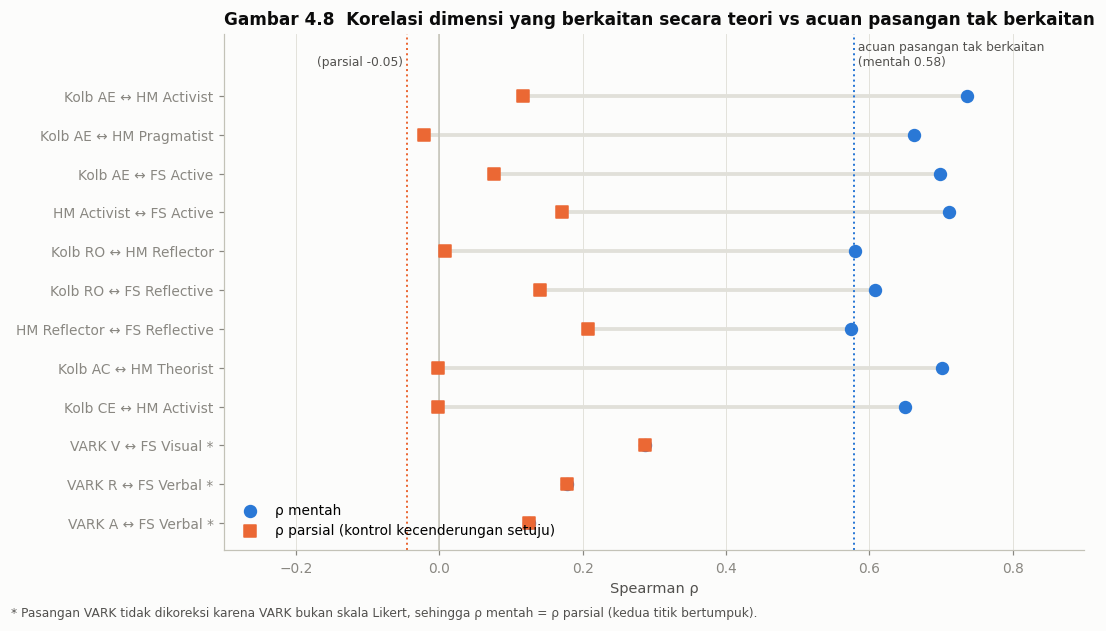

In [159]:
fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(konvergen))[::-1]
ax.hlines(y, konvergen["rho_parsial"], konvergen["rho_mentah"], color=GRID, linewidth=2.5)
ax.scatter(konvergen["rho_mentah"], y, s=60, color=SERI[0], label="ρ mentah", zorder=3)
ax.scatter(konvergen["rho_parsial"], y, s=60, color=SERI[1], marker="s", label="ρ parsial (kontrol kecenderungan setuju)", zorder=3)
ax.axvline(acuan["mentah"], color=SERI[0], linestyle=":", linewidth=1.3)
ax.axvline(acuan["parsial"], color=SERI[1], linestyle=":", linewidth=1.3)
ax.text(acuan["mentah"], len(y) - 0.3, f" acuan pasangan tak berkaitan\n (mentah {acuan['mentah']:.2f})", fontsize=8, color=INK2, va="bottom")
ax.text(acuan["parsial"], len(y) - 0.3, f"(parsial {acuan['parsial']:.2f}) ", fontsize=8, color=INK2, va="bottom", ha="right")
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, [p + (" *" if p.startswith("VARK") else "") for p in konvergen["pasangan"]])
ax.set_xlim(-0.3, 0.9); ax.set_ylim(-0.7, len(y) + 0.6)
fig.text(0.01, -0.01, "* Pasangan VARK tidak dikoreksi karena VARK bukan skala Likert, sehingga ρ mentah = ρ parsial (kedua titik bertumpuk).",
         fontsize=8, color=INK2)
ax.set_xlabel("Spearman ρ"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower left")
ax.set_title("Gambar 4.8  Korelasi dimensi yang berkaitan secara teori vs acuan pasangan tak berkaitan", loc="left")
fig.tight_layout()
simpan(fig, "4_8_kesesuaian_framework")

**Interpretasi:**
- **Korelasi mentah:** pasangan yang berkaitan secara teori berkorelasi ρ 0,57–0,74, tetapi **pasangan yang tidak berkaitan pun rata-rata ρ 0,58**. Tanpa koreksi, tidak ada bukti bahwa dimensi yang berkaitan lebih mirip daripada yang tidak berkaitan.
- **Setelah kecenderungan setuju dikendalikan:**
  - Pasangan tak berkaitan turun ke **≈ 0 (median −0,05)**.
  - Beberapa pasangan teori masih **sedikit positif**: HM Reflector ↔ FS Reflective (0,21), HM Activist ↔ FS Active (0,17), Kolb RO ↔ FS Reflective (0,14), dan Kolb AE ↔ HM Activist (0,12). Dimensi **aktif/reflektif** paling konsisten lintas framework.
  - Kolb AC ↔ HM Theorist, Kolb CE ↔ HM Activist, dan Kolb AE ↔ HM Pragmatist **turun ke ≈ 0**.
- **VARK V ↔ FS Visual (0,29)** adalah kesesuaian terkuat. Hubungan ini tidak terpengaruh gaya menjawab Likert.
- Pada level **label**, kuadran Kolb dan gaya HM dominan juga tidak sejalan (Cramér's V = 0,00 di 4.6.3, setelah kategori teknis dikeluarkan), meskipun HM dikembangkan dari siklus Kolb.

- **Dapat disimpulkan:** kesesuaian antar-framework **lemah**. Hanya dimensi yang isinya paling mirip (aktif/reflektif, visual) yang menunjukkan kesamaan.
- **Tidak dapat disimpulkan:**
  - Bahwa salah satu framework "tidak valid". Instrumen kelas ini adalah versi Likert yang pendek, dan koreksi parsial hanya pendekatan.
  - Bahwa keempat framework mengukur konstruk yang sama. Hasil ini justru menunjukkan sebaliknya.

### 4.8 Ringkasan temuan EDA dan implikasi untuk tahap berikutnya
| # | Temuan | Bukti | Implikasi |
|---|---|---|---|
| 1 | 192 dari 194 respons (99%) dapat dianalisis; sampel didominasi angkatan 2024 | 4.1, 4.2 | Generalisasi terbatas; sebutkan komposisi sampel di laporan |
| 2 | **Gaya menjawab "setuju" sangat kuat** pada item Likert | 4.5.2 (ρ skor–rata-rata 0,60–0,85) | Skor mentah HM/FS/Kolb bercampur dengan gaya menjawab |
| 3 | Efek plafon dan indeks bipolar mengumpul di 0 | 4.3, 4.3.1 | Banyak skor seri, sehingga muncul kategori teknis pada label |
| 4 | Kategori teknis besar: HM `Seri` 33%, FS `Setara` 32%, Kolb `Batas` 36,5%; kelas terkecil n = 18 | 4.4 | Untuk klasifikasi: stratifikasi, macro-F1, dan perhatian pada kelas minoritas |
| 5 | Missing IPS/IPK struktural, bukan acak | 4.5.1 | Jangan imputasi; analisis IPK hanya untuk n = 173 |
| 6 | Responden straightlining selalu jatuh ke kategori teknis HM/FS/Kolb | 4.5.3 | Laporkan analisis sensitivitas dengan dan tanpa responden ber-flag |
| 7 | VARK independen dari framework Likert; kesesuaian antar-framework lemah, baik pada skor maupun label | 4.6.1, 4.6.3, 4.7 | Perlakukan framework sebagai konstruk berbeda, jangan digabung menjadi satu skor |
| 8 | Hubungan skor/label dengan IPK lemah; hanya label VARK berbeda kecil (ε² = 0,085) | 4.6.2, 4.6.3 | IPK kurang menjanjikan sebagai target berbasis gaya belajar dengan data ini |

**Keterbatasan EDA:**
- Label dihitung dari item yang sama dengan skor, sesuai aturan dosen. Kategori teknis (`Seri`, `Setara`, `Batas`) bukan gaya belajar.
- Analisis bersifat deskriptif dan eksploratif, sehingga tidak ada klaim sebab-akibat.